# Classification of Autism Spectrum Disorder from Resting-State Functional Connectivity
### BrainCode 101 · ABIDE I

**Aim.** To test whether resting-state functional connectivity can distinguish individuals with autism spectrum disorder (ASD) from typically developing controls when the model is evaluated on an acquisition site it has never seen.

**Data.** ABIDE I, 846 participants (391 ASD, 455 controls) from 19 sites, preprocessed by the Preprocessed Connectomes Project.

**Method.** For each participant, the signals of 200 brain regions are summarised as a covariance matrix, which describes how strongly every pair of regions fluctuates together. Each matrix is stabilised (shrinkage), expressed as its deviation from a reference matrix (tangent space) and turned into one row of about 16,000 features. An L2-regularised logistic regression is trained on 18 sites and tested on the remaining site, in turn for all 19 sites.

**Result.** Balanced accuracy 0.691 and AUC 0.747 on unseen sites. None of 500 runs with shuffled diagnoses reached this level (p = 0.002).

**Model inputs.** Connectivity only. Age, sex, site and head motion are used only to check for confounding.

**Running the notebook**
* Select `Runtime > Run all` on a standard CPU runtime and approve the Google Drive request at the start.
* The first run takes about 3 hours. Every step is saved to `MyDrive/BrainCode101/ABIDE_final/`, so later runs reload finished steps and take a few minutes. After a disconnection, run all cells again.
* Figure cells show only their title and the figure. Click `Show code` to see the plotting code.

**Contents**
1. Setup
2. Background
3. Data
4. Functional connectivity
5. Covariance regularisation
6. Tangent-space representation
7. Feature vectors
8. Classification and evaluation
9. Results
10. Validity checks
11. Comparison with Abraham et al. (2017)
12. Alternative approaches tested
13. Limitations and future work
14. Technical notes
15. References

# 1. Setup
This cell installs nilearn (used only to download ABIDE), connects Google Drive and defines every analysis setting in one place. The settings and library versions are recorded in `config.json`, and `README.md` describes the output folder.

In [ ]:
# 1. Setup: install nilearn, connect Drive, create folders, define all settings (about 1 minute)
!pip install -q nilearn

import os, json, time, gc, warnings, platform, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import FancyBboxPatch
import scipy, sklearn, nilearn
from scipy.stats import rankdata, spearmanr, fisher_exact, mannwhitneyu
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, roc_curve, confusion_matrix
from sklearn.covariance import ledoit_wolf_shrinkage
from IPython.display import display
from google.colab import drive

drive.mount("/content/drive")

# folders
ROOT = Path("/content/drive/MyDrive/BrainCode101/ABIDE_final")
DIRS = {name: ROOT / name for name in
        ["01_data", "02_connectivity", "03_model", "04_results", "05_checks", "figures"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
for f in DIRS["figures"].glob("*.png"):   # figures are redrawn on every run
    f.unlink()
RAW_DIR = Path("/content/abide_raw")        # raw downloads stay on the fast local disk
RAW_DIR.mkdir(parents=True, exist_ok=True)

# all analysis settings
CONFIG = {
    "pipeline": "cpac", "band_pass_filtering": True, "global_signal_regression": False,
    "atlas": "rois_cc200", "quality_checked": True,
    "min_timepoints": 100,                 # section 3.4
    "kappa": 100.0,                        # target condition number, section 5.3
    "gm_max_iter": 15, "gm_tol": 1e-3,     # reference matrix, section 6.3
    "c_grid": np.logspace(-4, 1, 9).tolist(),
    "inner_folds": 4,                      # section 8.3
    "n_permutations": 500, "perm_seed_base": 10_000,
    "matched_fd_tolerance_mm": 0.01, "matched_seed": 0,
    "bootstrap_reps": 2000, "bootstrap_seed": 0,
    "demo_site": "CALTECH",                # site of the worked example in sections 3 to 7
}
C_GRID = np.array(CONFIG["c_grid"])
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
            "nilearn": nilearn.__version__, "matplotlib": matplotlib.__version__}
(ROOT / "config.json").write_text(json.dumps(
    {"config": CONFIG, "versions": VERSIONS,
     "written": datetime.datetime.now().isoformat(timespec="seconds")}, indent=2))
(ROOT / "README.md").write_text("\n".join([
    "# ABIDE_final",
    "Output folder of the BrainCode 101 ABIDE I notebook. Each step writes its results here when it finishes.",
    "",
    "* `01_data`: regional time series of the 871 quality-checked participants, phenotypic table, final list of 846 participants",
    "* `02_connectivity`: covariance matrices, shrinkage values per participant, the worked-example round",
    "* `03_model`: one file per cross-validation round for each model (predictions, selected C, inner scores; weights for the main model) and one predictions table per model",
    "* `04_results`: summary metrics, per-site results, comparison of shrinkage methods",
    "* `05_checks`: permutation test and its feature cache, head-motion analyses, MAX_MUN audit",
    "* `figures`: all figures as PNG files",
    "* `config.json`: analysis settings and library versions",
    "* `run_log.txt`: time-stamped log of every run",
]))

def log(msg):
    # print with a time stamp and append to run_log.txt
    line = f"{time.strftime('%Y-%m-%d %H:%M:%S')}  {msg}"
    print(line, flush=True)
    with open(ROOT / "run_log.txt", "a") as fh:
        fh.write(line + "\n")

def save_npz(path, **arrays):
    # write to a temporary file and rename, so an interrupted save never leaves a broken file
    path = Path(path)
    tmp = path.with_name(path.stem + ".tmp.npz")
    np.savez(tmp, **arrays)
    os.replace(tmp, path)

# plotting style shared by all figures
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 200, "font.size": 14,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "figure.titlesize": 18, "figure.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.width", 160)
COL = {"asd": "#D55E00", "ctrl": "#0072B2", "grey": "#666666", "light": "#D9D9D9",
       "green": "#009E73", "test": "#E69F00", "train": "#56B4E9", "box": "#F2F5F9"}

def show_save(fig, name):
    fig.savefig(DIRS["figures"] / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

def ipo_figure(title, widths=(1.0, 0.9, 1.0), height=5.2):
    # three panels (input, computation, output) joined by arrows
    fig = plt.figure(figsize=(17, height))
    gs = GridSpec(1, 5, figure=fig, wspace=0.06, top=0.80, bottom=0.12,
                  width_ratios=[widths[0], 0.16, widths[1], 0.22, widths[2]])
    axes = [fig.add_subplot(gs[j]) for j in (0, 2, 4)]
    for j, (x0, x1) in zip((1, 3), ((0.10, 0.90), (0.05, 0.50))):
        a = fig.add_subplot(gs[j]); a.axis("off")
        a.annotate("", xy=(x1, 0.5), xytext=(x0, 0.5), xycoords="axes fraction",
                   arrowprops=dict(arrowstyle="-|>", lw=5, color=COL["grey"], mutation_scale=35))
    fig.suptitle(title, y=0.98)
    return fig, axes

def process_box(ax, title, lines, size=13.5):
    ax.axis("off")
    ax.add_patch(FancyBboxPatch((0.02, 0.03), 0.96, 0.94, transform=ax.transAxes,
                                boxstyle="round,pad=0.01,rounding_size=0.05",
                                fc=COL["box"], ec=COL["grey"], lw=1.5))
    ax.text(0.5, 0.92, title, ha="center", va="top", fontsize=16, weight="bold", transform=ax.transAxes)
    ax.text(0.5, 0.78, "\n".join(lines), ha="center", va="top", fontsize=size,
            linespacing=1.6, transform=ax.transAxes)

def log_axis(ax):
    # readable log-scale ticks for head motion (FD, mm)
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(matplotlib.ticker.FixedLocator([0.02, 0.05, 0.1, 0.2, 0.5, 1.0]))
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# metric helpers
def ba(y_true, prob):
    # balanced accuracy at the 0.5 threshold
    return balanced_accuracy_score(y_true, (np.asarray(prob) > 0.5).astype(int))

def within_rho(a, b, groups):
    # Spearman correlation of a and b after removing group means of the ranks (group = site and diagnosis)
    a, b, groups = np.asarray(a, float), np.asarray(b, float), np.asarray(groups)
    ok = np.isfinite(a) & np.isfinite(b)
    d = pd.DataFrame({"a": rankdata(a[ok]), "b": rankdata(b[ok]), "g": groups[ok]})
    d[["a", "b"]] = d.groupby("g")[["a", "b"]].transform(lambda v: v - v.mean())
    den = d.a.std() * d.b.std()
    return float((d.a * d.b).mean() / den) if den > 0 else np.nan

log(f"setup complete, project folder: {ROOT}")
print(json.dumps(VERSIONS, indent=1))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 77.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 94.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
Mounted at /content/drive
2026-10-20 18:08:55  setup complete, project folder: /content/drive/MyDrive/BrainCode101/ABIDE_final
{
 "python": "3.13.16",
 "numpy": "2.1.3",
 "pandas": "3.0.6",
 "scipy": "1.16.3",
 "scikit-learn": "1.6.1",
 "nilearn": "0.14.1",
 "matplotlib": "3.10.0"
}


# 2. Background

### 2.1 Functional MRI and the BOLD signal
Functional MRI measures the blood-oxygen-level-dependent (BOLD) signal, an indirect marker of neural activity. Active regions receive more oxygenated blood, which slightly changes the MRI signal. A whole-brain image is acquired every 1.5 to 3 seconds over a scan of roughly 5 to 10 minutes. In resting-state fMRI, participants perform no task, and each region's signal fluctuates spontaneously.

### 2.2 Functional connectivity
Biswal et al. (1995) showed that regions belonging to the same functional system fluctuate together at rest. Two regions whose signals are temporally correlated are described as functionally connected. The full set of such relationships for one participant is referred to as the functional connectome.

### 2.3 The ABIDE I dataset
Reported connectivity differences in autism are inconsistent across studies, partly because of small samples. The Autism Brain Imaging Data Exchange (ABIDE I) aggregated 1,112 resting-state scans (539 ASD, 573 controls) from 17 international sites (Di Martino et al., 2014).

### 2.4 Classification task and site effects
Each site used a different scanner and protocol and recruited different proportions of ASD and control participants. A classifier can therefore reach high accuracy by recognising the site rather than the brain.

Leave-one-site-out cross-validation removes this shortcut:
* the model is trained on 18 sites and tested on the remaining site
* this is repeated so that every site is tested once
* every prediction therefore comes from a model that never saw that participant's site

This is the stricter of the two schemes used by Abraham et al. (2017), the main reference for this project.

### 2.5 Overview of the pipeline
Figure 1 shows each step and what it produces for one participant. Sections 3 to 8 follow the same order, and each section states its input and output.

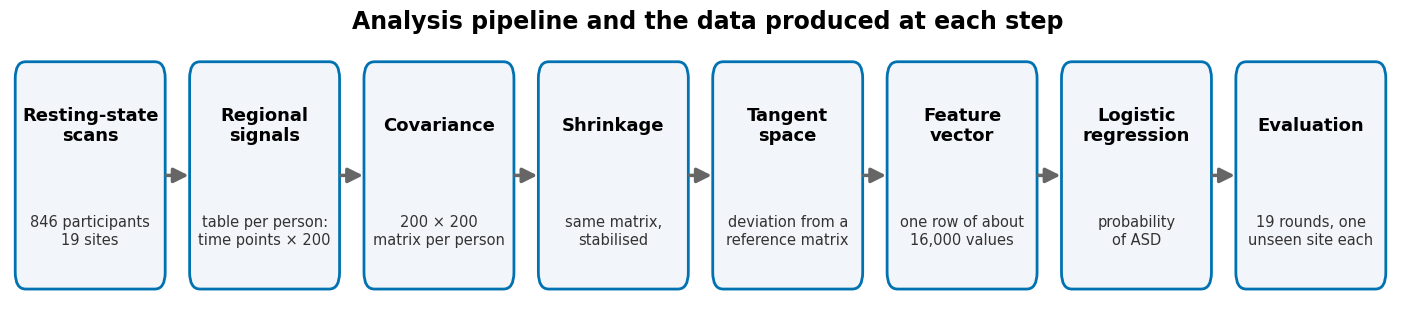

In [ ]:
# @title Figure 1. Analysis pipeline and the data produced at each step
steps = [
    ("Resting-state\nscans", "846 participants\n19 sites"),
    ("Regional\nsignals", "table per person:\ntime points × 200"),
    ("Covariance", "200 × 200\nmatrix per person"),
    ("Shrinkage", "same matrix,\nstabilised"),
    ("Tangent\nspace", "deviation from a\nreference matrix"),
    ("Feature\nvector", "one row of about\n16,000 values"),
    ("Logistic\nregression", "probability\nof ASD"),
    ("Evaluation", "19 rounds, one\nunseen site each"),
]
fig, ax = plt.subplots(figsize=(18, 3.6))
ax.set_xlim(0, len(steps)); ax.set_ylim(0, 1); ax.axis("off")
for k, (head, sub) in enumerate(steps):
    ax.add_patch(FancyBboxPatch((k + 0.04, 0.10), 0.84, 0.80, boxstyle="round,pad=0.01,rounding_size=0.06",
                                fc=COL["box"], ec=COL["ctrl"], lw=2))
    ax.text(k + 0.46, 0.68, head, ha="center", va="center", fontsize=13, weight="bold")
    ax.text(k + 0.46, 0.30, sub, ha="center", va="center", fontsize=10.5, color="#333333")
    if k < len(steps) - 1:
        ax.annotate("", xy=(k + 1.04, 0.5), xytext=(k + 0.88, 0.5),
                    arrowprops=dict(arrowstyle="-|>", lw=2.5, color=COL["grey"], mutation_scale=22))
ax.set_title("Analysis pipeline and the data produced at each step", fontsize=17, pad=6)
show_save(fig, "fig01_pipeline")

# 3. Data

### 3.1 Preprocessing by the Preprocessed Connectomes Project
The data were downloaded from the Preprocessed Connectomes Project (PCP; Craddock et al., 2013), processed with the C-PAC pipeline:
* **Motion correction** realigns all volumes to correct for head movement.
* **Spatial normalisation** registers each brain to the MNI152 template, so that a given region occupies the same location in every participant.
* **Nuisance regression** removes 24 motion-related signals (Friston et al., 1996), five noise components from white matter and cerebrospinal fluid (CompCor; Behzadi et al., 2007), and linear and quadratic drift.
* **Band-pass filtering between 0.01 and 0.1 Hz** keeps fluctuations with a period of 10 to 100 seconds. Resting-state connectivity is concentrated in this range (Biswal et al., 1995); slower components mainly reflect scanner drift and faster ones mainly respiration and cardiac noise.
* **No global signal regression.** The whole-brain mean signal was kept, because removing it can introduce artificial negative correlations (Murphy et al., 2009) and distort group differences in autism (Gotts et al., 2013).
* **The cc200 atlas** divides the brain into 200 regions defined by clustering voxels with similar resting signals (Craddock et al., 2012). Each region's signal is the average of its voxels.

### 3.2 Quality control
Participants were included if they passed nilearn's quality-control rule, which combines the ratings of three PCP raters (rater 1: OK; rater 2: OK or maybe; rater 3: OK). This leaves 871 participants (403 ASD, 468 controls), the same set analysed by Abraham et al. (2017).

### 3.3 Downloaded data
**Output of this step:** two kinds of tables.
* **Regional time series:** one table per participant, with one row per time point and one column per region (200 columns). Scan length differs between sites, so the number of rows differs between participants.
* **Phenotypic table:** one row per participant, with site, diagnosis, age, sex and head motion.

In [ ]:
# 3.3 Download the data, or load the copy saved on Drive
BUNDLE = DIRS["01_data"] / "abide1_cc200_filt_noglobal_qc871.npz"
PHENO_CSV = DIRS["01_data"] / "phenotypic_qc871.csv"

if BUNDLE.exists() and PHENO_CSV.exists():
    z = np.load(BUNDLE, allow_pickle=True)
    ts_all = list(z["ts"])
    pheno_all = pd.read_csv(PHENO_CSV)
    log(f"loaded saved data: {len(ts_all)} participants")
else:
    from nilearn.datasets import fetch_abide_pcp
    log("downloading ABIDE I from the Preprocessed Connectomes Project (about 20 minutes)")
    abide = fetch_abide_pcp(data_dir=str(RAW_DIR), pipeline=CONFIG["pipeline"],
                            band_pass_filtering=CONFIG["band_pass_filtering"],
                            global_signal_regression=CONFIG["global_signal_regression"],
                            derivatives=[CONFIG["atlas"]], quality_checked=CONFIG["quality_checked"],
                            verbose=1)
    ts_all = [np.asarray(t, dtype=np.float32) for t in abide[CONFIG["atlas"]]]
    pheno_all = pd.DataFrame(abide["phenotypic"]).reset_index(drop=True)
    assert len(ts_all) == len(pheno_all), "time series and phenotypic table differ in length"
    ts_obj = np.empty(len(ts_all), dtype=object)        # one array per participant (lengths differ)
    for i, t in enumerate(ts_all):
        ts_obj[i] = t
    np.savez_compressed(BUNDLE, ts=ts_obj)
    pheno_all.to_csv(PHENO_CSV, index=False)
    log(f"downloaded and saved {len(ts_all)} participants")

y_all    = (pheno_all["DX_GROUP"].astype(int).values == 1).astype(int)    # ABIDE coding: 1 = ASD, 2 = control
site_all = pheno_all["SITE_ID"].astype(str).values
T_all    = np.array([t.shape[0] for t in ts_all])                          # time points per participant

# integrity checks
n_regions = {t.shape[1] for t in ts_all}
n_bad = sum(not np.isfinite(t).all() for t in ts_all)
print(f"participants: {len(ts_all)} | ASD {y_all.sum()} | control {(y_all == 0).sum()} | site labels: {len(set(site_all))}")
print(f"regions per participant: {n_regions} | participants with missing or infinite values: {n_bad}")
print(f"time points per participant: min {T_all.min()}, median {int(np.median(T_all))}, max {T_all.max()}")
assert len(ts_all) == 871, f"expected 871 quality-checked participants, found {len(ts_all)}; check the download"
assert n_regions == {200} and n_bad == 0, "unexpected number of regions or invalid values"

2026-10-20 18:09:01  loaded saved data: 871 participants
participants: 871 | ASD 403 | control 468 | site labels: 20
regions per participant: {200} | participants with missing or infinite values: 0
time points per participant: min 78, median 176, max 316


In [ ]:
# 3.3 Look at the downloaded tables
ex_all = int(np.where((site_all == CONFIG["demo_site"]) & (y_all == 1))[0][0])   # worked-example participant
show_cols = ["SUB_ID", "SITE_ID", "DX_GROUP", "AGE_AT_SCAN", "SEX", "func_mean_fd"]
print(f"Phenotypic table: {len(pheno_all)} rows (participants); first 5 rows of selected columns")
print("DX_GROUP: 1 = ASD, 2 = control | SEX: 1 = male, 2 = female | func_mean_fd: head motion in mm")
display(pheno_all[show_cols].head())
X0 = np.asarray(ts_all[ex_all])
print(f"\nRegional time series of participant {pheno_all['SUB_ID'].iloc[ex_all]} ({site_all[ex_all]}): "
      f"{X0.shape[0]} rows (time points) × {X0.shape[1]} columns (regions); first 5 rows and 8 columns")
display(pd.DataFrame(X0[:5, :8], columns=[f"region {r}" for r in range(8)],
                     index=pd.Index(range(5), name="time point")).round(1))

Phenotypic table: 871 rows (participants); first 5 rows of selected columns
DX_GROUP: 1 = ASD, 2 = control | SEX: 1 = male, 2 = female | func_mean_fd: head motion in mm


,SUB_ID,SITE_ID,DX_GROUP,AGE_AT_SCAN,SEX,func_mean_fd
0,50003,PITT,1,24.45,1,0.322092
1,50004,PITT,1,19.09,1,0.127745
2,50005,PITT,1,13.73,2,0.128136
3,50006,PITT,1,13.37,1,0.070143
4,50007,PITT,1,17.78,1,0.151246



Regional time series of participant 51461 (CALTECH): 146 rows (time points) × 200 columns (regions); first 5 rows and 8 columns


,region 0,region 1,region 2,region 3,region 4,region 5,region 6,region 7
time point,,,,,,,,
0,-14.500000,-7.900000,-6.400000,-3.000000,14.200000,6.9,12.0,8.7
1,-25.100000,-29.600000,-13.800000,-13.900000,15.300000,15.9,3.1,5.0
2,-25.799999,-50.799999,-31.100000,-12.400000,-2.100000,14.6,-6.2,4.6
3,-13.300000,-53.000000,-43.799999,7.500000,-25.700001,9.9,-3.1,13.7
4,9.200000,-30.299999,-36.500000,32.799999,-34.099998,12.7,11.7,31.9


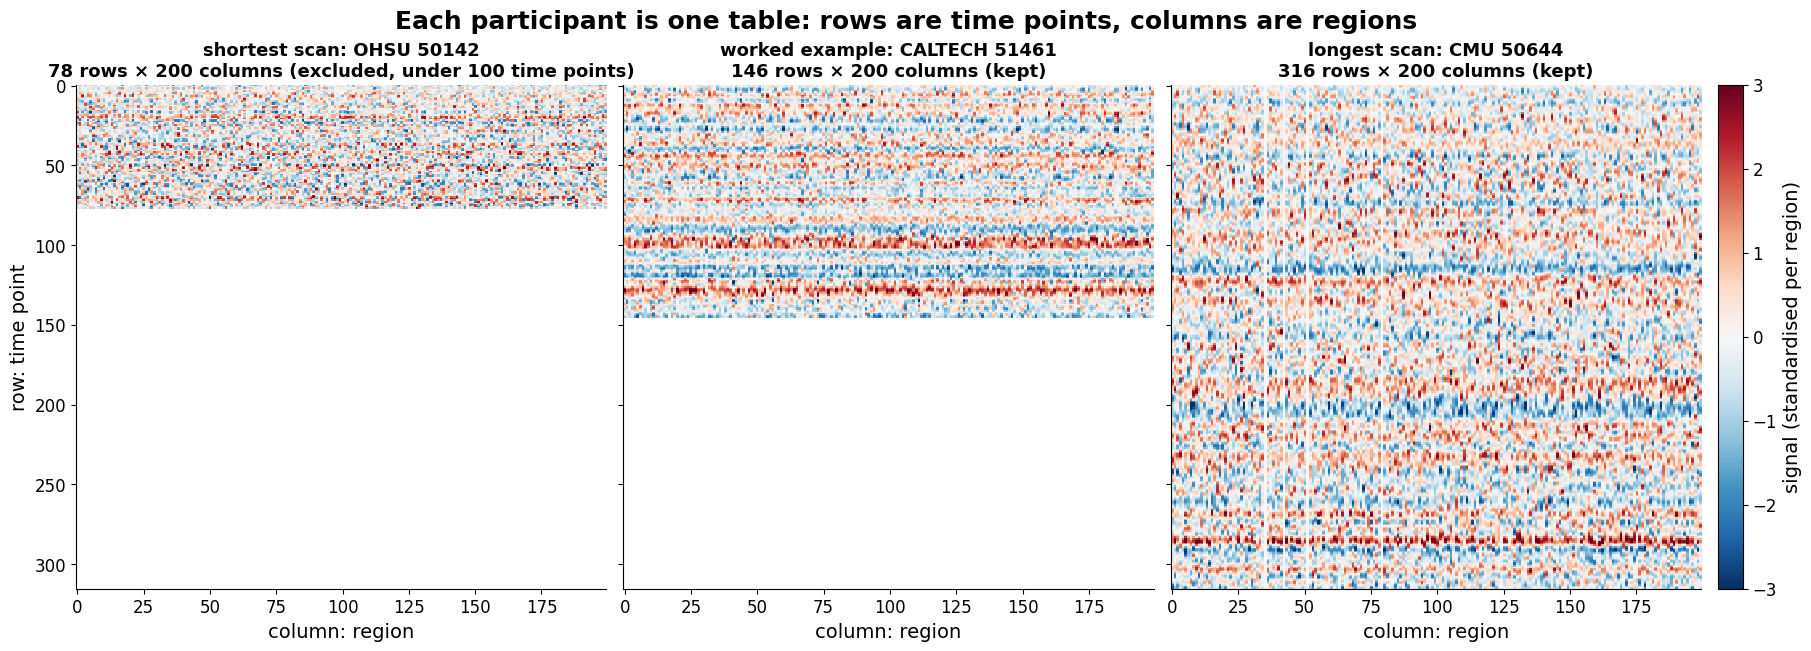

In [ ]:
# @title Figure 2. Regional time series of three participants
picks = [(int(np.argmin(T_all)), "shortest scan"), (ex_all, "worked example"), (int(np.argmax(T_all)), "longest scan")]
fig, axs = plt.subplots(1, 3, figsize=(18, 6.4), sharey=True, layout="constrained")
for ax, (i, lab) in zip(axs, picks):
    X_ = np.asarray(ts_all[i], dtype=float)
    sd_ = X_.std(0)
    Zs = np.where(sd_ > 0, (X_ - X_.mean(0)) / np.where(sd_ > 0, sd_, 1), 0)
    im = ax.imshow(Zs, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, interpolation="nearest",
                   extent=(-0.5, X_.shape[1] - 0.5, X_.shape[0] - 0.5, -0.5))
    status = "kept" if T_all[i] >= CONFIG["min_timepoints"] else f"excluded, under {CONFIG['min_timepoints']} time points"
    ax.set_title(f"{lab}: {site_all[i]} {pheno_all['SUB_ID'].iloc[i]}\n{X_.shape[0]} rows × {X_.shape[1]} columns ({status})",
                 fontsize=13)
    ax.set_xlabel("column: region")
axs[0].set_ylabel("row: time point"); axs[0].set_ylim(T_all.max() - 0.5, -0.5)
fig.colorbar(im, ax=axs, fraction=0.025, pad=0.01, label="signal (standardised per region)")
fig.suptitle("Each participant is one table: rows are time points, columns are regions")
show_save(fig, "fig02_time_series_tables")

### 3.4 Inclusion criterion: minimum scan length
A covariance matrix estimated from a short scan is unreliable (section 5). Participants with fewer than 100 time points were excluded, which removes 25 participants, all from OHSU. The threshold is a project decision rather than a published standard: a threshold of 150 would exclude 207 participants, about a quarter of the sample.

The 17 ABIDE institutions appear as 20 site labels, because some contributed two separate samples (for example `UCLA_1` and `UCLA_2`). Removing OHSU leaves 19 sites.

**Output of this step:** the final sample of 846 participants, saved as one table with one row per participant.

In [ ]:
# 3.4 Final sample: participants with at least 100 time points
keep_mask = T_all >= CONFIG["min_timepoints"]
print(f"excluded (fewer than {CONFIG['min_timepoints']} time points), by site:")
print(pd.Series(site_all[~keep_mask]).value_counts().to_string())

idx = np.where(keep_mask)[0]
ts      = [np.asarray(ts_all[i], dtype=np.float64) for i in idx]
ph      = pheno_all.iloc[idx].reset_index(drop=True)
y       = y_all[idx]
site    = site_all[idx]
T_sub   = T_all[idx]
sub_id  = ph["SUB_ID"].astype(str).values
file_id = ph["FILE_ID"].astype(str).values
age     = pd.to_numeric(ph["AGE_AT_SCAN"], errors="coerce").values
sex     = pd.to_numeric(ph["SEX"], errors="coerce").values                 # 1 = male, 2 = female
fd      = pd.to_numeric(ph["func_mean_fd"], errors="coerce").values        # mean framewise displacement (mm), checks only
perc_fd = pd.to_numeric(ph["func_perc_fd"], errors="coerce").values        # percentage of high-motion volumes, checks only
batch   = np.array(["_".join(f.split("_")[:-1]).upper() for f in file_id]) # file-name prefix, used in section 10.3

N = len(y)
SITES = sorted(np.unique(site))
IDX = {s: np.where(site == s)[0] for s in SITES}
GROUP = np.char.add(np.char.add(site.astype(str), "|"), y.astype(str))   # site and diagnosis, used by the checks

# regions with a constant signal lay outside the field of view for that participant
dead = np.array([t.std(axis=0) == 0 for t in ts])                         # participants × 200, True = excluded
R_FULL = dead.shape[1]
alive_all = ~dead.any(axis=0)
R_ALIVE = int(alive_all.sum())

subjects = pd.DataFrame({"sub_id": sub_id, "file_id": file_id, "site": site, "batch": batch,
                         "dx": np.where(y == 1, "ASD", "control"), "age": age, "sex": sex,
                         "mean_fd": fd, "perc_fd": perc_fd, "timepoints": T_sub,
                         "n_excluded_regions": dead.sum(1)})
subjects.to_csv(DIRS["01_data"] / "subjects_846.csv", index=False)

print(f"\nfinal sample: {N} participants | ASD {y.sum()} | control {(y == 0).sum()} | sites {len(SITES)}")
print(f"regions constant in at least one participant: {int(dead.any(0).sum())} | "
      f"participants affected: {int(dead.any(1).sum())} | regions present in all: {R_ALIVE}")
assert N == 846 and len(SITES) == 19, "the final sample should contain 846 participants from 19 sites"
log("final sample saved to 01_data/subjects_846.csv")

print("\nFinal participant table: first 5 rows")
display(subjects.head())

excluded (fewer than 100 time points), by site:
OHSU    25

final sample: 846 participants | ASD 391 | control 455 | sites 19
regions constant in at least one participant: 21 | participants affected: 15 | regions present in all: 179
2026-10-20 18:09:04  final sample saved to 01_data/subjects_846.csv

Final participant table: first 5 rows


,sub_id,file_id,site,batch,dx,age,sex,mean_fd,perc_fd,timepoints,n_excluded_regions
0,50003,Pitt_0050003,PITT,PITT,ASD,24.45,1,0.322092,67.164179,196,0
1,50004,Pitt_0050004,PITT,PITT,ASD,19.09,1,0.127745,14.427861,196,0
2,50005,Pitt_0050005,PITT,PITT,ASD,13.73,2,0.128136,10.945274,196,0
3,50006,Pitt_0050006,PITT,PITT,ASD,13.37,1,0.070143,1.492537,196,0
4,50007,Pitt_0050007,PITT,PITT,ASD,17.78,1,0.151246,18.905473,196,0


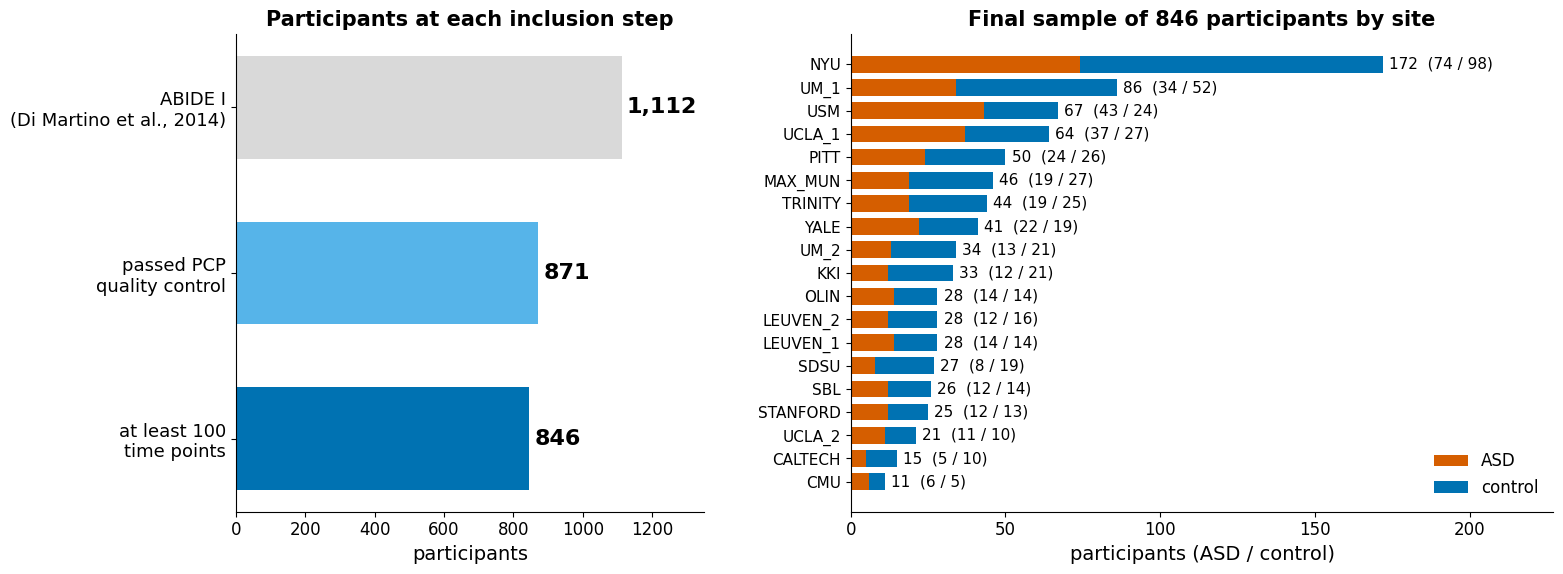

In [ ]:
# @title Figure 3. Participants at each inclusion step and by site
tab = (subjects.groupby("site")["dx"].value_counts().unstack(fill_value=0)
       .reindex(columns=["ASD", "control"]).assign(n=lambda d: d.sum(axis=1)).sort_values("n"))
fig = plt.figure(figsize=(17, 6.2))
gs = GridSpec(1, 2, figure=fig, width_ratios=[0.8, 1.2], wspace=0.25)

ax = fig.add_subplot(gs[0])
stages = [("ABIDE I\n(Di Martino et al., 2014)", 1112),
          ("passed PCP\nquality control", len(ts_all)),
          (f"at least {CONFIG['min_timepoints']}\ntime points", N)]
for k, (lab, n) in enumerate(stages):
    ax.barh(len(stages) - 1 - k, n, color=[COL["light"], COL["train"], COL["ctrl"]][k], height=0.62)
    ax.text(n + 15, len(stages) - 1 - k, f"{n:,}", va="center", fontsize=16, weight="bold")
ax.set_yticks(range(len(stages))); ax.set_yticklabels([s[0] for s in stages][::-1], fontsize=13)
ax.set_xlim(0, 1350); ax.set_xlabel("participants")
ax.set_title("Participants at each inclusion step")

ax = fig.add_subplot(gs[1])
yy = np.arange(len(tab))
ax.barh(yy, tab["ASD"], color=COL["asd"], label="ASD", height=0.72)
ax.barh(yy, tab["control"], left=tab["ASD"], color=COL["ctrl"], label="control", height=0.72)
for k, (a_, c_) in enumerate(zip(tab["ASD"], tab["control"])):
    ax.text(a_ + c_ + 2, k, f"{a_ + c_}  ({a_} / {c_})", va="center", fontsize=11)
ax.set_yticks(yy); ax.set_yticklabels(tab.index, fontsize=11)
ax.set_xlim(0, tab["n"].max() * 1.32); ax.set_xlabel("participants (ASD / control)")
ax.set_title(f"Final sample of {N} participants by site"); ax.legend(frameon=False, loc="lower right")
show_save(fig, "fig03_participants")

### 3.5 Potential confounds
These variables could act as shortcuts for a classifier, so they are described before modelling (Figure 4):
* **Site.** Scanner and diagnostic composition differ between sites. Addressed by leave-one-site-out cross-validation.
* **Head motion.** Even submillimetre movement alters measured connectivity (Power et al., 2012; Van Dijk et al., 2012; Satterthwaite et al., 2012), and participants with ASD often move more (Deen & Pelphrey, 2012). Motion is measured as mean framewise displacement (FD), the average head displacement between consecutive volumes in millimetres. In this sample, participants with ASD moved 38% more on average (printed below the figure). Assessed in section 10.2.
* **Age and sex.** Ages range from children to adults, with the same median in both groups (about 15 years). The sample is mostly male: 54 of 391 ASD participants and 90 of 455 controls are female.
* **Scan length.** The number of time points differs between sites (Figure 4A). For 422 of the 846 participants it is smaller than the number of regions, which matters in section 5.

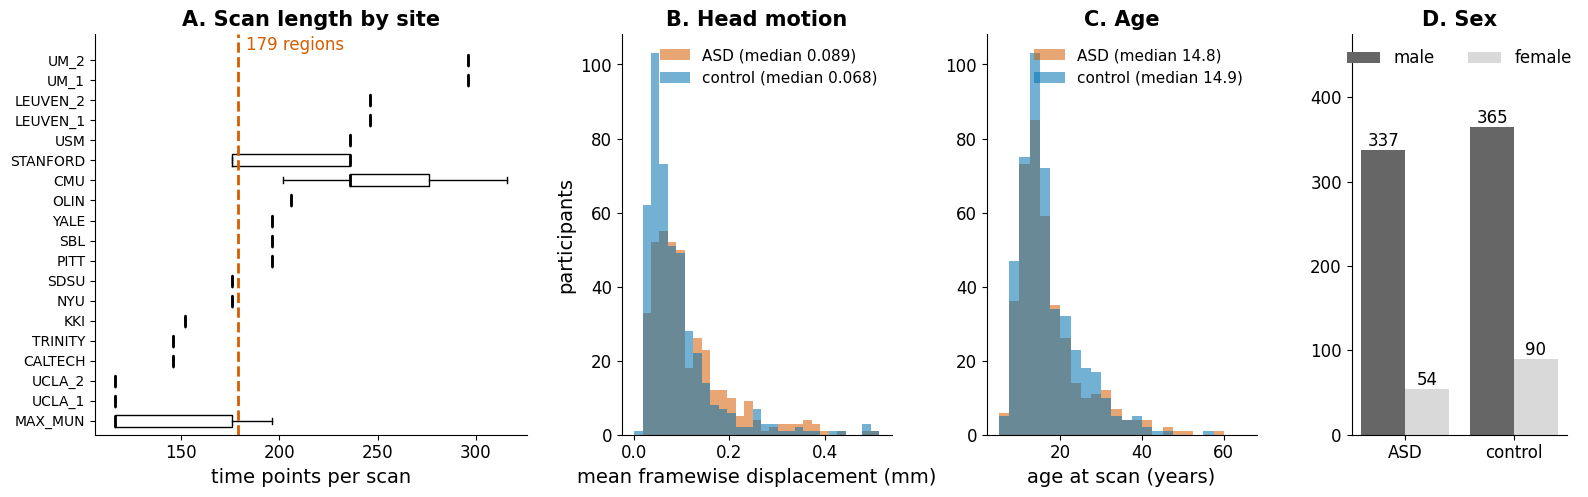

mean FD: ASD 0.128 mm, control 0.093 mm (ASD +38%), Mann-Whitney p = 7.7e-08
participants with fewer time points than the 179 regions: 422 of 846


In [ ]:
# @title Figure 4. Scan length, head motion, age and sex
fig, axs = plt.subplots(1, 4, figsize=(19, 5.2), gridspec_kw=dict(width_ratios=[1.6, 1, 1, 0.8], wspace=0.32))

ax = axs[0]
order = sorted(SITES, key=lambda s: np.median(T_sub[IDX[s]]))
mpl_ver = tuple(int(v) for v in matplotlib.__version__.split(".")[:2])
horiz = {"orientation": "horizontal"} if mpl_ver >= (3, 10) else {"vert": False}
ax.boxplot([T_sub[IDX[s]] for s in order], widths=0.6, showfliers=False,
           medianprops=dict(color="black", lw=2), **horiz)
ax.axvline(R_ALIVE, color=COL["asd"], ls="--", lw=2)
ax.set_ylim(0.3, len(order) + 1.3)
ax.text(R_ALIVE + 4, len(order) + 0.75, f"{R_ALIVE} regions", color=COL["asd"], fontsize=12, va="center")
ax.set_yticks(range(1, len(order) + 1)); ax.set_yticklabels(order, fontsize=10)
ax.set_xlabel("time points per scan"); ax.set_title("A. Scan length by site")

ax = axs[1]
bins = np.linspace(0, np.nanpercentile(fd, 99), 30)
for g, c, lab in [(1, COL["asd"], "ASD"), (0, COL["ctrl"], "control")]:
    v = fd[(y == g) & np.isfinite(fd)]
    ax.hist(v, bins=bins, color=c, alpha=0.55, label=f"{lab} (median {np.median(v):.3f})")
ax.set_xlabel("mean framewise displacement (mm)"); ax.set_ylabel("participants")
ax.legend(frameon=False, fontsize=11); ax.set_title("B. Head motion")

ax = axs[2]
bins = np.arange(5, 66, 2.5)
for g, c, lab in [(1, COL["asd"], "ASD"), (0, COL["ctrl"], "control")]:
    v = age[(y == g) & np.isfinite(age)]
    ax.hist(v, bins=bins, color=c, alpha=0.55, label=f"{lab} (median {np.median(v):.1f})")
ax.set_xlabel("age at scan (years)"); ax.legend(frameon=False, fontsize=11); ax.set_title("C. Age")

ax = axs[3]
cnt = pd.crosstab(np.where(sex == 2, "female", "male"), np.where(y == 1, "ASD", "control"))
xx = np.arange(2)
ax.bar(xx - 0.2, cnt.loc["male"], 0.4, color=COL["grey"], label="male")
ax.bar(xx + 0.2, cnt.loc["female"], 0.4, color=COL["light"], label="female")
for k, grp in enumerate(["ASD", "control"]):
    ax.text(k - 0.2, cnt.loc["male", grp] + 5, cnt.loc["male", grp], ha="center", fontsize=12)
    ax.text(k + 0.2, cnt.loc["female", grp] + 5, cnt.loc["female", grp], ha="center", fontsize=12)
ax.set_ylim(0, cnt.values.max() * 1.3)
ax.set_xticks(xx); ax.set_xticklabels(["ASD", "control"]); ax.legend(frameon=False, ncol=2, loc="upper center")
ax.set_title("D. Sex")
show_save(fig, "fig04_confounds")

p_fd = mannwhitneyu(fd[(y == 1) & np.isfinite(fd)], fd[(y == 0) & np.isfinite(fd)]).pvalue
print(f"mean FD: ASD {np.nanmean(fd[y == 1]):.3f} mm, control {np.nanmean(fd[y == 0]):.3f} mm "
      f"(ASD {np.nanmean(fd[y == 1]) / np.nanmean(fd[y == 0]) - 1:+.0%}), Mann-Whitney p = {p_fd:.1e}")
print(f"participants with fewer time points than the {R_ALIVE} regions: {(T_sub < R_ALIVE).sum()} of {N}")

# 4. Functional connectivity

### 4.1 Covariance between regional signals
**Input:** one participant's time-series table (time points × 200 regions). **Output:** one 200 × 200 covariance matrix.

Covariance measures whether two regions' signals rise and fall together. A toy example with three regions and five time points shows each step.

**Start: the signals**

| | time 1 | time 2 | time 3 | time 4 | time 5 | mean |
|---|---|---|---|---|---|---|
| region A | 1 | 4 | 7 | 4 | 4 | **4** |
| region B | 1 | 3 | 5 | 3 | 3 | **3** |
| region C | 5 | 3 | 1 | 3 | 3 | **3** |

**Step 1. Subtract each region's mean.** This keeps only how the signal moves above and below its own average.

| | time 1 | time 2 | time 3 | time 4 | time 5 |
|---|---|---|---|---|---|
| A minus 4 | -3 | 0 | 3 | 0 | 0 |
| B minus 3 | -2 | 0 | 2 | 0 | 0 |
| C minus 3 | 2 | 0 | -2 | 0 | 0 |

**Step 2. Multiply two regions' values at each time point.** Two values on the same side of their means give a positive product. Values on opposite sides give a negative one.

| | time 1 | time 2 | time 3 | time 4 | time 5 | sum |
|---|---|---|---|---|---|---|
| A × B | (-3) × (-2) = **6** | 0 | 3 × 2 = **6** | 0 | 0 | 12 |
| A × C | (-3) × 2 = **-6** | 0 | 3 × (-2) = **-6** | 0 | 0 | -12 |

**Step 3. Divide the sum by the number of time points (5).** This is the average product, which is the covariance.

| pair | sum ÷ 5 | covariance | meaning |
|---|---|---|---|
| A and B | 12 ÷ 5 | **2.4** | move together |
| A and C | -12 ÷ 5 | **-2.4** | move in opposite directions |
| A and A | 18 ÷ 5 | **3.6** | how much A fluctuates (its variance) |

**Step 4. Do this for every pair and put the results in one table.**

| | A | B | C |
|---|---|---|---|
| **A** | 3.6 | 2.4 | -2.4 |
| **B** | 2.4 | 1.6 | -1.6 |
| **C** | -2.4 | -1.6 | 1.6 |

Reading the table:
* **Positive** (2.4): the two regions move together. **Negative** (-2.4): they move in opposite directions. **Near 0**: unrelated.
* Time has been averaged out, so every participant gets a 200 × 200 table, whatever the length of the scan.

In [ ]:
# 4.1 Covariance matrix for every participant
COV = DIRS["02_connectivity"] / "covariances_cc200.npz"

def sample_cov(X):
    # X: time points × regions. Subtract each region's mean, multiply, average over time (divide by T)
    Xc = X - X.mean(axis=0, keepdims=True)
    return (Xc.T @ Xc) / Xc.shape[0]

if COV.exists():
    z = np.load(COV)
    S_full, alpha_lw = z["S_full"], z["alpha_lw"]
    assert S_full.shape == (N, R_FULL, R_FULL), "saved covariance matrices do not match the final sample"
    log("loaded covariance matrices from Drive")
else:
    t0 = time.time()
    S_full = np.stack([sample_cov(t) for t in ts])          # 846 × 200 × 200; excluded regions give zero rows
    # Ledoit-Wolf shrinkage amount per participant, used only by the comparison model (section 8.6);
    # computed on the regions present in all participants, as in the earlier Ledoit-Wolf run
    alpha_lw = np.array([ledoit_wolf_shrinkage(t[:, alive_all], assume_centered=False) for t in ts])
    save_npz(COV, S_full=S_full, alpha_lw=alpha_lw, dead=dead, sub_id=sub_id)
    log(f"computed {N} covariance matrices in {time.time() - t0:.0f} s")

assert np.allclose(S_full, np.swapaxes(S_full, 1, 2)), "covariance matrices must be symmetric"
assert (np.diagonal(S_full, axis1=1, axis2=2) >= 0).all(), "variances cannot be negative"
print(f"covariance matrices: {S_full.shape} (participants × regions × regions)")

# worked example used in sections 3 to 7: the first ASD participant at the demonstration site
DEMO = CONFIG["demo_site"]
EX = int(IDX[DEMO][np.argmax(y[IDX[DEMO]] == 1)])
print(f"worked example: participant {sub_id[EX]} ({'ASD' if y[EX] else 'control'}), site {site[EX]}, {T_sub[EX]} time points")

2026-10-20 18:09:12  loaded covariance matrices from Drive
covariance matrices: (846, 200, 200) (participants × regions × regions)
worked example: participant 51461 (ASD), site CALTECH, 146 time points


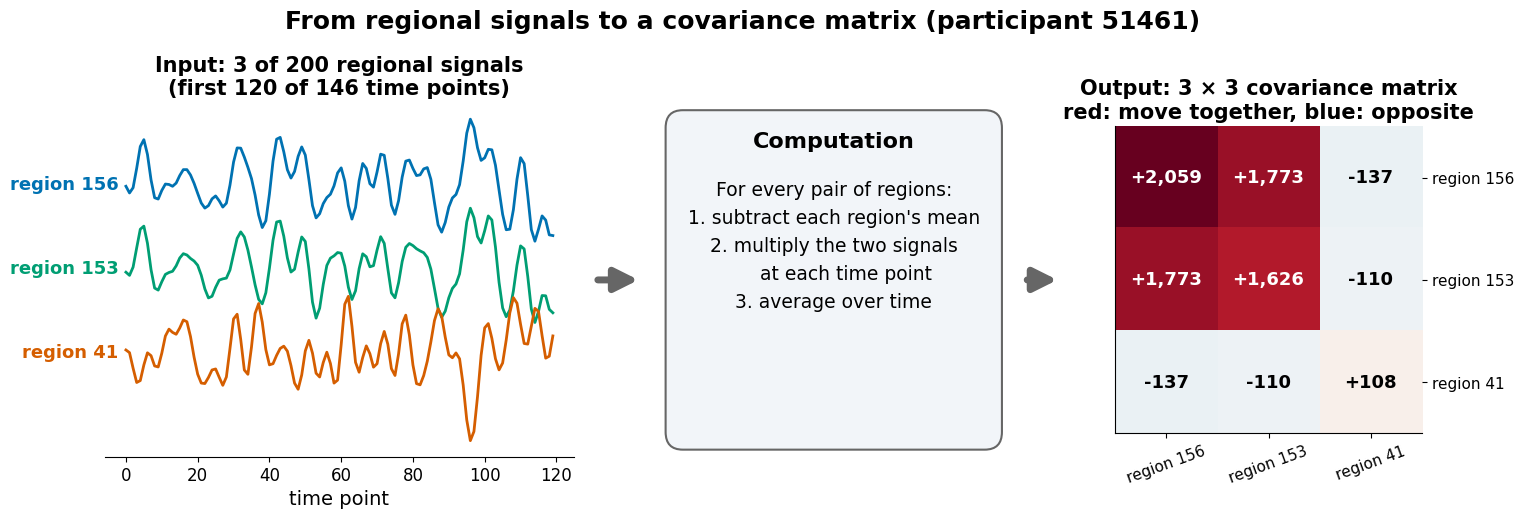

In [ ]:
# @title Figure 5. From regional signals to a covariance matrix
X = ts[EX]
regs = np.where(~dead[EX])[0]
Cx = np.corrcoef(X[:, regs].T); np.fill_diagonal(Cx, 0)
a_ = regs[np.unravel_index(np.argmax(Cx), Cx.shape)[0]]     # three regions that illustrate the idea:
b_ = regs[np.argmax(Cx[list(regs).index(a_)])]              # b moves most with a
c_ = regs[np.argmin(Cx[list(regs).index(a_)])]              # c moves most against a
three = [a_, b_, c_]
names = [f"region {r}" for r in three]
S3 = S_full[EX][np.ix_(three, three)]

fig, (a1, a2, a3) = ipo_figure(f"From regional signals to a covariance matrix (participant {sub_id[EX]})",
                               widths=(1.3, 0.95, 0.85))
show_t = min(120, X.shape[0])
for k, (r, col) in enumerate(zip(three, [COL["ctrl"], COL["green"], COL["asd"]])):
    sig = X[:show_t, r]
    a1.plot(np.arange(show_t), (sig - sig.mean()) / sig.std() - 3.2 * k, color=col, lw=2)
    a1.text(-2, -3.2 * k, names[k], ha="right", va="center", fontsize=13, color=col, weight="bold")
a1.set_yticks([]); a1.spines["left"].set_visible(False); a1.set_xlabel("time point")
a1.set_title(f"Input: 3 of 200 regional signals\n(first {show_t} of {X.shape[0]} time points)")

process_box(a2, "Computation", ["For every pair of regions:", "1. subtract each region's mean",
                                "2. multiply the two signals", "    at each time point",
                                "3. average over time"])

vmax = np.abs(S3).max()
fmt = "{:+,.0f}" if vmax >= 100 else "{:+.2f}"
a3.imshow(S3, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
for i in range(3):
    for j in range(3):
        a3.text(j, i, fmt.format(S3[i, j]), ha="center", va="center", fontsize=13, weight="bold",
                color="white" if abs(S3[i, j]) > 0.6 * vmax else "black")
a3.set_xticks(range(3)); a3.set_yticks(range(3))
a3.set_xticklabels(names, rotation=20, fontsize=11); a3.set_yticklabels(names, fontsize=11)
a3.yaxis.tick_right()
a3.set_title("Output: 3 × 3 covariance matrix\nred: move together, blue: opposite")
show_save(fig, "fig05_covariance_example")

### 4.2 Covariance versus correlation
Correlation is covariance rescaled to lie between -1 and 1, which makes it easier to read: 0.6 means that two signals move **closely** together and 0 that they are unrelated. The model uses covariance because the tangent-space method in section 6 is defined on covariance matrices (Varoquaux et al., 2010; Abraham et al., 2017). Correlation is used only to display matrices, as in the right panel of Figure 6.

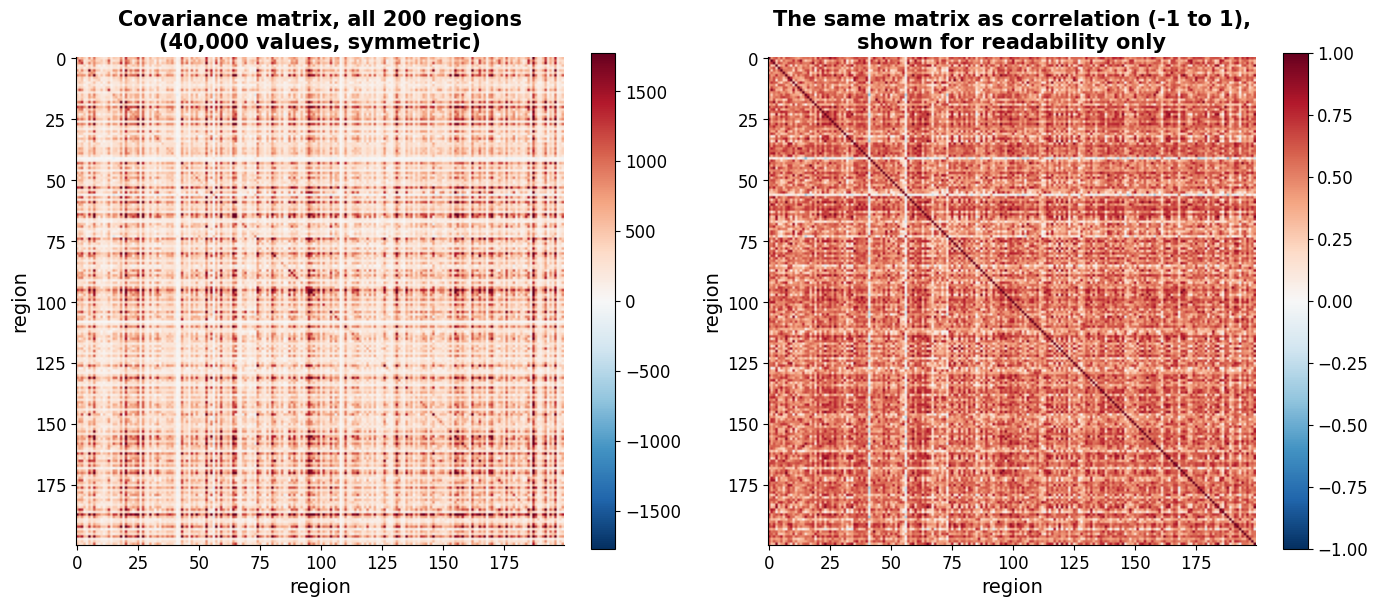

In [ ]:
# @title Figure 6. Covariance matrix of one participant, all regions
fig, axs = plt.subplots(1, 2, figsize=(14, 6.4))
S = S_full[EX]
v = np.percentile(np.abs(S), 99)
im = axs[0].imshow(S, cmap="RdBu_r", vmin=-v, vmax=v)
axs[0].set_title(f"Covariance matrix, all {R_FULL} regions\n({R_FULL * R_FULL:,} values, symmetric)")
plt.colorbar(im, ax=axs[0], fraction=0.046)
sd = np.sqrt(np.diag(S)); ok = sd > 0
Rr = np.zeros_like(S); Rr[np.ix_(ok, ok)] = S[np.ix_(ok, ok)] / np.outer(sd[ok], sd[ok])
im = axs[1].imshow(Rr, cmap="RdBu_r", vmin=-1, vmax=1)
axs[1].set_title("The same matrix as correlation (-1 to 1),\nshown for readability only")
plt.colorbar(im, ax=axs[1], fraction=0.046)
for ax in axs: ax.set_xlabel("region"); ax.set_ylabel("region")
fig.tight_layout()
show_save(fig, "fig06_covariance_full")

### 4.3 Regions without signal
In 15 participants, 21 regions have a constant signal. They lie at the edges of the brain, mainly in the frontal pole, orbitofrontal cortex, temporal pole and cerebellum, areas at the border of the scanned volume or prone to signal loss. A constant signal carries no information, so these regions are removed (Figure 7).

Which regions to remove is decided in each cross-validation round from the training participants only, so the test site cannot influence the features. Between 179 and 183 regions are kept per round; 179 are present in every participant.

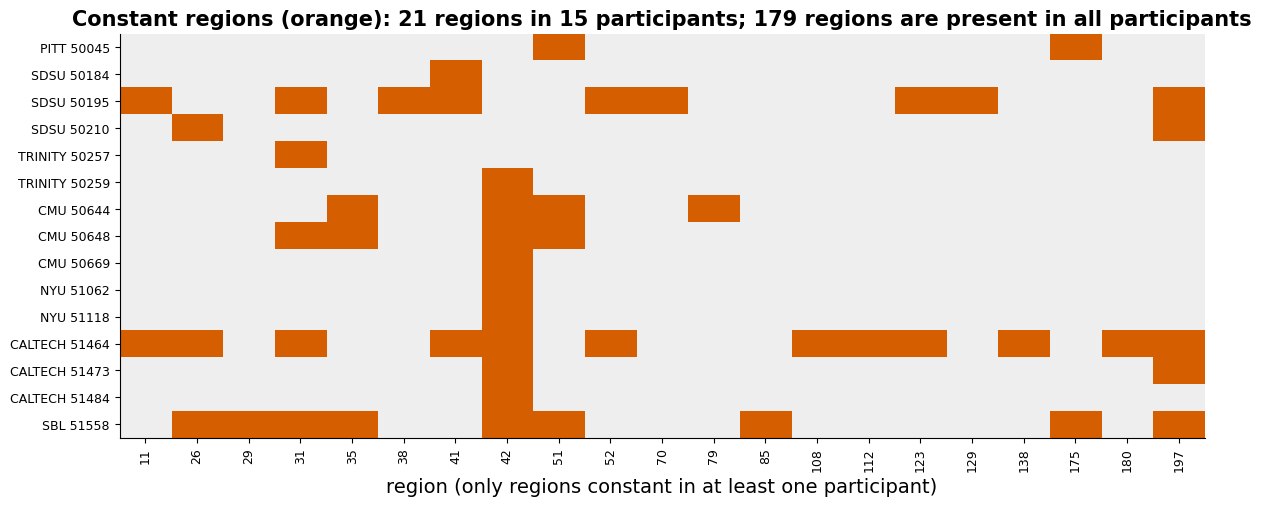

In [ ]:
# @title Figure 7. Regions without signal
ppl = np.where(dead.any(1))[0]; rg = np.where(dead.any(0))[0]
fig, ax = plt.subplots(figsize=(14, max(3.0, 0.25 * len(ppl) + 1.5)))
ax.imshow(dead[np.ix_(ppl, rg)], cmap=matplotlib.colors.ListedColormap(["#EEEEEE", COL["asd"]]), aspect="auto")
ax.set_yticks(range(len(ppl))); ax.set_yticklabels([f"{site[i]} {sub_id[i]}" for i in ppl], fontsize=9)
ax.set_xticks(range(len(rg))); ax.set_xticklabels(rg, fontsize=9, rotation=90)
ax.set_xlabel("region (only regions constant in at least one participant)")
ax.set_title(f"Constant regions (orange): {len(rg)} regions in {len(ppl)} participants; "
             f"{R_ALIVE} regions are present in all participants")
show_save(fig, "fig07_regions_without_signal")

# 5. Covariance regularisation

### 5.1 Why raw covariance matrices are unstable
**Input:** the 846 covariance matrices. **Output:** the same matrices, stabilised by shrinkage.

A covariance matrix can be described by independent directions of variation, like the long and short axes of a cloud of data points. The variance along each direction is called an eigenvalue. The tangent-space step (section 6) takes the logarithm of every eigenvalue, so a zero eigenvalue makes it fail, and very small eigenvalues make it highly sensitive to noise. The condition number, the ratio of the largest to the smallest eigenvalue, summarises this: it is infinite when an eigenvalue is zero.

A toy example with two regions whose signals are exactly proportional:
```
time          1      2      3      4
region A      1      2      3      4
region B      2      4      6      8        (always twice A)

covariance    1.25   2.50
              2.50   5.00
eigenvalues   6.25 and 0                    (all points lie on one line: no variation across it)
```
A matrix of 179 regions has 179 eigenvalues, but a scan with T time points can show variation in at most T minus 1 directions. In these data all 846 raw matrices had at least one zero eigenvalue, including scans longer than 179 time points (printed below). In Figure 8, the longest scan (316 time points) has fewer than 100 non-zero eigenvalues. This is most likely because band-pass filtering and nuisance regression (section 3.1) remove part of the independent variation in each signal.

### 5.2 Shrinkage toward a matrix without connections
Shrinkage blends each covariance matrix with a simple matrix that has the same average variance on the diagonal and zeros everywhere else, that is, no connections. Continuing the toy example with a blend of 10% and an average variance of 3.125:
```
0.9 × covariance  +  0.1 × (3.125   0    )   =   1.44   2.25
                           (0       3.125)       2.25   4.81

eigenvalues   5.94 and 0.31                 (no longer zero)
```
The smallest eigenvalue rises from 0 to 0.31, the connection weakens slightly from 2.50 to 2.25, and the overall pattern is kept. The blend amount sets this trade-off; section 5.3 explains how it is chosen.

In [ ]:
# 5.2 Eigenvalues before and after condition-number matching (regions present in all participants)
def cond_alpha(lmax, lmin, m, kappa):
    # shrinkage amount that gives condition number kappa (0 if the matrix is already better conditioned)
    lmin = np.maximum(lmin, 0.0)
    num = lmax - kappa * lmin
    return np.clip(np.where(num <= 0, 0.0, num / np.maximum(m * (kappa - 1.0) + num, 1e-15)), 0.0, 0.999)

S_alive = S_full[:, alive_all][:, :, alive_all]
eig_raw = np.linalg.eigvalsh(S_alive)                      # eigenvalues in ascending order, per participant
m_avg = eig_raw.mean(1)                                    # mean variance (trace divided by number of regions)
a_cond = cond_alpha(eig_raw[:, -1], eig_raw[:, 0], m_avg, CONFIG["kappa"])

def cond_after(alpha):
    lo = (1 - alpha) * np.maximum(eig_raw[:, 0], 0) + alpha * m_avg
    hi = (1 - alpha) * eig_raw[:, -1] + alpha * m_avg
    return hi / lo
k_cond = cond_after(a_cond)
del S_alive; gc.collect()

nonzero = (eig_raw > 1e-6 * m_avg[:, None]).sum(1)                  # eigenvalues above the floor used in Figure 8
print(f"participants with fewer time points than regions ({R_ALIVE}): {(T_sub < R_ALIVE).sum()} of {N}")
print(f"raw matrices with a zero smallest eigenvalue (up to rounding): {(eig_raw[:, 0] <= 1e-10 * eig_raw[:, -1]).sum()} of {N}")
print(f"non-zero eigenvalues per raw matrix: median {np.median(nonzero):.0f}, range {nonzero.min()} to {nonzero.max()} "
      f"(of {R_ALIVE}); longest scan ({T_sub.max()} time points): {nonzero[np.argmax(T_sub)]}")
print(f"shrinkage amount with condition-number matching: median {np.median(a_cond):.2f}, "
      f"range {a_cond.min():.2f} to {a_cond.max():.2f}")
print(f"condition number after condition-number matching: median {np.median(k_cond):.0f}, "
      f"range {k_cond.min():.0f} to {k_cond.max():.0f}")

participants with fewer time points than regions (179): 422 of 846
raw matrices with a zero smallest eigenvalue (up to rounding): 846 of 846
non-zero eigenvalues per raw matrix: median 68, range 57 to 112 (of 179); longest scan (316 time points): 91
shrinkage amount with condition-number matching: median 0.35, range 0.21 to 0.56
condition number after condition-number matching: median 100, range 100 to 100


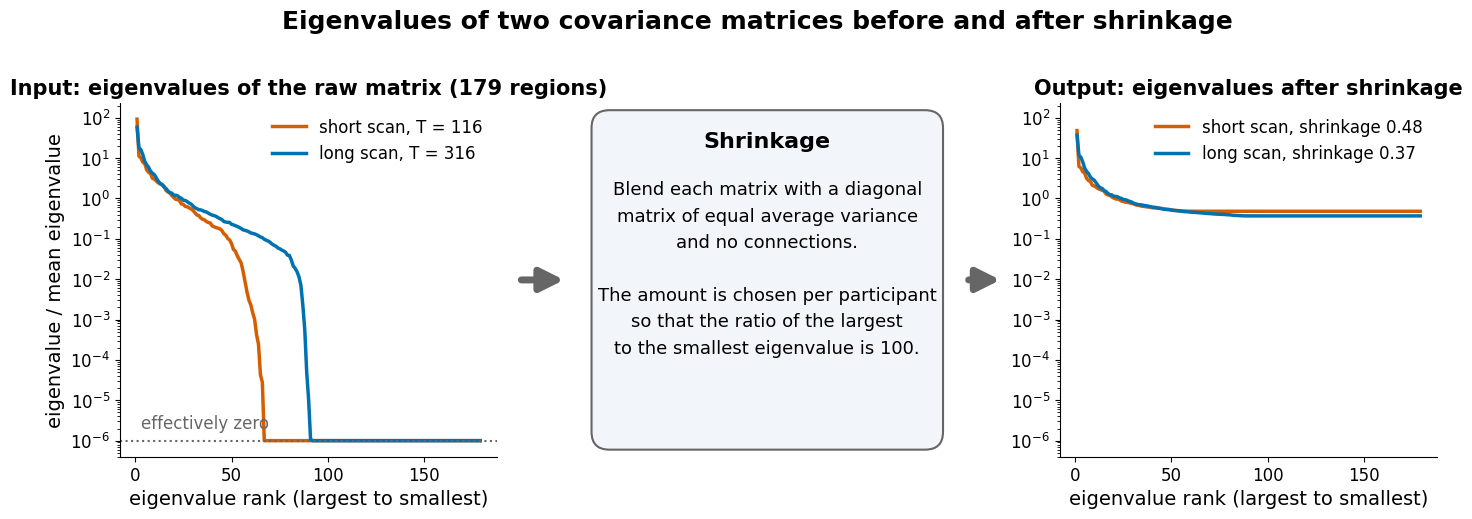

In [ ]:
# @title Figure 8. Eigenvalues before and after shrinkage
short_p = int(np.argmin(np.where(T_sub >= 110, T_sub, 10_000)))    # a participant with a short scan
long_p = int(np.argmax(T_sub))                                      # a participant with a long scan
rank = np.arange(1, R_ALIVE + 1)
floor = 1e-6

fig, (a1, a2, a3) = ipo_figure("Eigenvalues of two covariance matrices before and after shrinkage",
                               widths=(1, 0.95, 1))
for p, col, lab in [(short_p, COL["asd"], "short scan"), (long_p, COL["ctrl"], "long scan")]:
    lam = eig_raw[p][::-1] / m_avg[p]
    a1.semilogy(rank, np.maximum(lam, floor), color=col, lw=2.5, label=f"{lab}, T = {T_sub[p]}")
a1.axhline(floor, color=COL["grey"], ls=":", lw=1.5)
a1.text(3, floor * 2, "effectively zero", fontsize=12, color=COL["grey"])
a1.set_xlabel("eigenvalue rank (largest to smallest)"); a1.set_ylabel("eigenvalue / mean eigenvalue")
a1.legend(frameon=False, loc="upper right"); a1.set_title(f"Input: eigenvalues of the raw matrix ({R_ALIVE} regions)")

process_box(a2, "Shrinkage", ["Blend each matrix with a diagonal", "matrix of equal average variance",
                              "and no connections.", "",
                              "The amount is chosen per participant", "so that the ratio of the largest",
                              f"to the smallest eigenvalue is {CONFIG['kappa']:.0f}."], size=13)

for p, col, lab in [(short_p, COL["asd"], "short scan"), (long_p, COL["ctrl"], "long scan")]:
    lam = ((1 - a_cond[p]) * np.maximum(eig_raw[p], 0) + a_cond[p] * m_avg[p])[::-1] / m_avg[p]
    a3.semilogy(rank, lam, color=col, lw=2.5, label=f"{lab}, shrinkage {a_cond[p]:.2f}")
a3.set_ylim(a1.get_ylim()); a3.set_xlabel("eigenvalue rank (largest to smallest)")
a3.legend(frameon=False, loc="upper right"); a3.set_title("Output: eigenvalues after shrinkage")
show_save(fig, "fig08_shrinkage_eigenvalues")

### 5.3 Choice of shrinkage amount
Two rules for choosing the amount were compared:
* **Ledoit-Wolf** (Ledoit & Wolf, 2004), used by Abraham et al. (2017) and by our first model, estimates the amount from each participant's own data. In these data it blended at most 14% and the amount tracked scan length (printed below). After Ledoit-Wolf the condition number still ranged from 179 to 6,659, so participants were stabilised to very different degrees, and how much depended on the site's scan length (Figure 9).
* **Condition-number matching**, used for the final model, chooses for each participant the amount that brings the condition number to exactly 100. Every matrix is then equally stable, whatever the scan length. It blends more strongly than Ledoit-Wolf (Figure 9, left). This is a simplified form of condition-number regularisation (Won et al., 2013) and an engineering choice of this project.

Both rules are run through the full classification in section 8, and section 9.4 compares their performance. Both targets gave the same balanced accuracy (0.691), and 100 was kept. Because both were evaluated on the same sites reported here, the final estimate may be slightly optimistic.


In [ ]:
# 5.3 Ledoit-Wolf shrinkage on the same matrices, for comparison
k_lw = cond_after(alpha_lw)
rho_lw = spearmanr(T_sub, alpha_lw).correlation
rho_site = spearmanr([T_sub[IDX[s]].mean() for s in SITES], [alpha_lw[IDX[s]].mean() for s in SITES]).correlation
print(f"Ledoit-Wolf amount: {alpha_lw.min():.3f} to {alpha_lw.max():.3f}; rank correlation with scan length: "
      f"{rho_lw:+.2f} across participants, {rho_site:+.2f} across site means")
print(f"condition number after Ledoit-Wolf: median {np.median(k_lw):.0f}, range {k_lw.min():.0f} to {k_lw.max():.0f}")
pd.DataFrame({"sub_id": sub_id, "site": site, "timepoints": T_sub, "shrinkage_ledoit_wolf": alpha_lw,
              "shrinkage_condition_matched": a_cond, "condition_number_ledoit_wolf": k_lw,
              "condition_number_matched": k_cond}).to_csv(DIRS["02_connectivity"] / "shrinkage_per_participant.csv", index=False)

Ledoit-Wolf amount: 0.015 to 0.142; rank correlation with scan length: -0.65 across participants, -0.92 across site means
condition number after Ledoit-Wolf: median 1079, range 179 to 6659


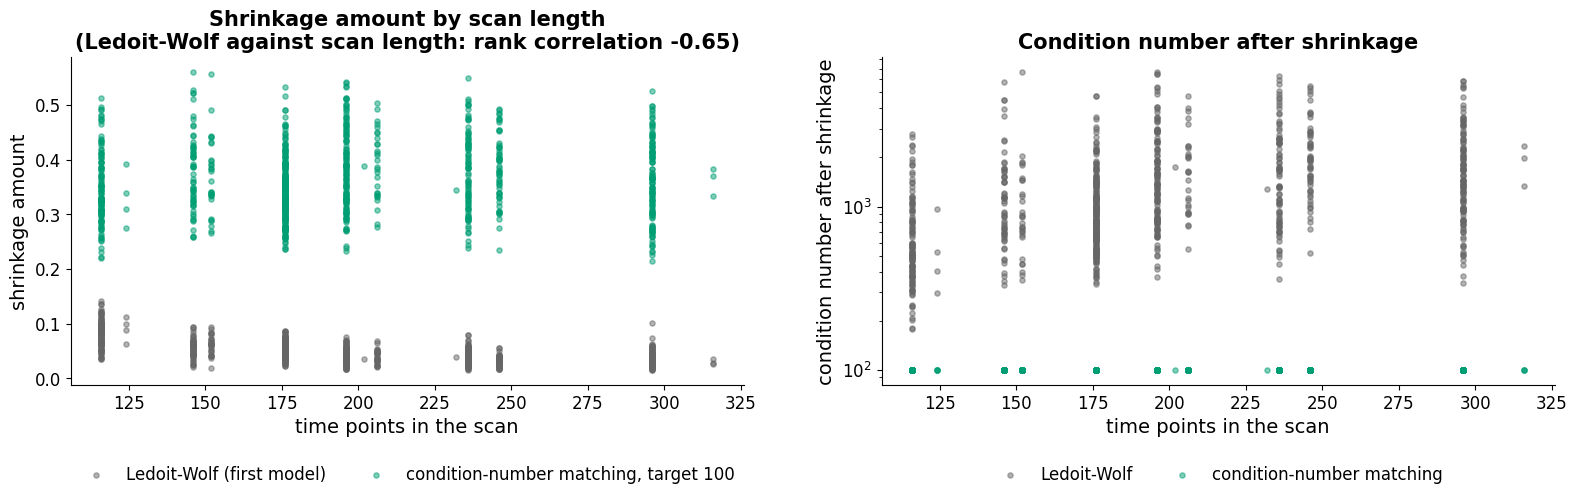

In [ ]:
# @title Figure 9. Shrinkage amount and condition number by scan length
fig, axs = plt.subplots(1, 2, figsize=(16, 5.4))
axs[0].scatter(T_sub, alpha_lw, s=14, alpha=0.5, color=COL["grey"], label="Ledoit-Wolf (first model)")
axs[0].scatter(T_sub, a_cond, s=14, alpha=0.5, color=COL["green"], label=f"condition-number matching, target {CONFIG['kappa']:.0f}")
axs[0].set_xlabel("time points in the scan"); axs[0].set_ylabel("shrinkage amount")
axs[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=12)
axs[0].set_title(f"Shrinkage amount by scan length\n(Ledoit-Wolf against scan length: rank correlation {rho_lw:+.2f})")
axs[1].scatter(T_sub, k_lw, s=14, alpha=0.5, color=COL["grey"], label="Ledoit-Wolf")
axs[1].scatter(T_sub, k_cond, s=14, alpha=0.5, color=COL["green"], label="condition-number matching")
axs[1].set_yscale("log"); axs[1].set_xlabel("time points in the scan")
axs[1].set_ylabel("condition number after shrinkage")
axs[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=12)
axs[1].set_title("Condition number after shrinkage")
fig.tight_layout()
show_save(fig, "fig09_shrinkage_by_scan_length")

# 6. Tangent-space representation

### 6.1 Why differences are not enough
**Input:** the stabilised covariance matrices.

**Output:** for each participant, a matrix of deviations from a reference matrix.

The aim is to describe how each participant's connectivity differs from a typical pattern. Covariance matrices must stay symmetric with positive eigenvalues, so they lie on a curved space rather than a flat one, and plain subtraction distorts the differences between them. Tangent-space connectivity was introduced for group comparisons by Varoquaux et al. (2010). Abraham et al. (2017) and the benchmark of Dadi et al. (2019) found it the most accurate connectivity representation for predicting diagnosis.

### 6.2 Log-ratio comparison of a single value
For a single positive value, differences are better measured as the logarithm of a ratio. With a reference value of 2, a value of 4 (double) gives log(4/2) = 0.69, a value of 1 (half) gives log(1/2) = -0.69, and a value of 2 gives 0. Doubling and halving are changes of equal size and receive values of equal magnitude, whereas plain subtraction would give +2 and -1 (Figure 10).

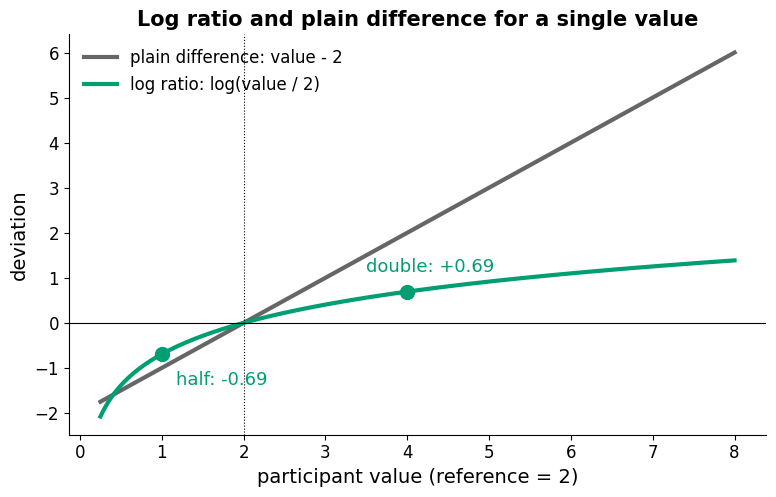

In [ ]:
# @title Figure 10. Log ratio and plain difference for a single value
fig, ax = plt.subplots(figsize=(9, 5.2))
xv = np.linspace(0.25, 8, 300)
ax.plot(xv, xv - 2, color=COL["grey"], lw=3, label="plain difference: value - 2")
ax.plot(xv, np.log(xv / 2), color=COL["green"], lw=3, label="log ratio: log(value / 2)")
for xx_, lab in [(1, "half"), (4, "double")]:
    ax.plot([xx_], [np.log(xx_ / 2)], "o", color=COL["green"], ms=10)
    ax.annotate(f"{lab}: {np.log(xx_ / 2):+.2f}", (xx_, np.log(xx_ / 2)), textcoords="offset points",
                 xytext=(10, -22) if xx_ == 1 else (-30, 14), fontsize=13, color=COL["green"])
ax.axhline(0, color="black", lw=0.8); ax.axvline(2, color="black", lw=0.8, ls=":")
ax.set_xlabel("participant value (reference = 2)"); ax.set_ylabel("deviation")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Log ratio and plain difference for a single value")
show_save(fig, "fig10_log_ratio")

### 6.3 Reference matrix and projection
The same principle is applied to whole matrices in two steps:
1. **Reference matrix.** The geometric mean of the training participants' matrices (Moakher, 2005; Pennec et al., 2006) is the matrix version of the geometric mean of numbers; for example, the geometric mean of 1 and 4 is 2. It is computed iteratively, starting from the ordinary average, from the training sites only in each round. ASD and control participants are pooled, so the reference does not use diagnosis.
2. **Projection.** Each participant's matrix is expressed relative to the reference and transformed with a matrix logarithm.

The result is a symmetric matrix of deviations from the reference. Positive values roughly correspond to connections stronger than in the reference, negative values to weaker connections, and values near zero to typical connections. Because the whole matrix is transformed together, each value also depends on the other connections, so it is not an exact measure of a single region pair.

The cell below defines the computations of sections 5 to 7 and checks them on small examples.

In [ ]:
# 6.3 Core computations: shrinkage, reference matrix, tangent projection, vectorisation
EPS = 1e-15

def _sym(M):
    # enforce exact symmetry (removes rounding error)
    return 0.5 * (M + np.swapaxes(M, -1, -2))

def _spd_pow(M, p):
    # matrix power via the eigendecomposition: raise each eigenvalue to p
    w, v = np.linalg.eigh(_sym(M))
    return (v * (np.maximum(w, EPS) ** p)[..., None, :]) @ np.swapaxes(v, -1, -2)

def _sym_logm(M):
    # matrix logarithm: logarithm of each eigenvalue
    w, v = np.linalg.eigh(_sym(M))
    return (v * np.log(np.maximum(w, EPS))[..., None, :]) @ np.swapaxes(v, -1, -2)

def _sym_expm(M):
    # matrix exponential, the inverse of the matrix logarithm
    w, v = np.linalg.eigh(_sym(M))
    return (v * np.exp(w)[..., None, :]) @ np.swapaxes(v, -1, -2)

def shrink_cov(S, mode, kappa=100.0, alpha=None):
    # section 5: blend with a diagonal matrix; amount chosen per matrix ("cond") or given ("lw")
    S = _sym(np.asarray(S, dtype=np.float64))
    n, p, _ = S.shape
    m = np.trace(S, axis1=1, axis2=2) / p
    if mode == "cond":
        w = np.linalg.eigvalsh(S)
        a = cond_alpha(w[:, -1], w[:, 0], m, kappa)
    elif mode == "lw":
        a = np.asarray(alpha, dtype=np.float64).reshape(n)
    else:
        raise ValueError(mode)
    return _sym((1 - a)[:, None, None] * S + (a * m)[:, None, None] * np.eye(p)), a

def geometric_mean(C, max_iter=CONFIG["gm_max_iter"], tol=CONFIG["gm_tol"]):
    # section 6.3: reference matrix, starting from the arithmetic mean
    G = _sym(C.mean(axis=0))
    step, prev, it, grad = 1.0, np.inf, 0, np.inf
    for it in range(1, max_iter + 1):
        Gm, Gp = _spd_pow(G, -0.5), _spd_pow(G, 0.5)
        L = _sym_logm(Gm @ C @ Gm).mean(axis=0)     # mean deviation of all matrices from G
        grad = float(np.linalg.norm(L))
        if grad < tol:                                # G is the centre
            break
        if grad > prev:                               # overshoot: halve the step
            step *= 0.5
        prev = grad
        G = _sym(Gp @ _sym_expm(step * L) @ Gp)       # move G toward the centre
    return G, {"iterations": it, "final_change": grad}

def tangent(C, ref):
    # section 6.3: express C relative to the reference and take the matrix logarithm
    W = _spd_pow(ref, -0.5)
    return _sym_logm(W @ C @ W)

def flatten(M):
    # section 7.1: lower triangle including the diagonal; diagonal divided by sqrt(2) (nilearn convention)
    R = M.shape[-1]
    rows, cols = np.tril_indices(R)
    out = M[..., rows, cols].copy()
    out[..., rows == cols] /= np.sqrt(2.0)
    return out

def build_fold_features(tr, te, mode="cond"):
    # region exclusion and the reference matrix are derived from the training participants (tr) only
    keep = ~dead[tr].any(axis=0)
    sl = np.ix_(keep, keep)
    Str = np.stack([S_full[i][sl] for i in tr])
    Ste = np.stack([S_full[i][sl] for i in te])
    Ctr, _ = shrink_cov(Str, mode, CONFIG["kappa"], alpha_lw[tr] if mode == "lw" else None)
    Cte, _ = shrink_cov(Ste, mode, CONFIG["kappa"], alpha_lw[te] if mode == "lw" else None)
    ref, info = geometric_mean(Ctr)
    Xtr, Xte = flatten(tangent(Ctr, ref)), flatten(tangent(Cte, ref))
    assert np.isfinite(Xtr).all() and np.isfinite(Xte).all(), "non-finite features"
    return Xtr, Xte, dict(keep=keep, ref=ref, Cte=Cte, **info)

# checks on small examples (all should print True)
two = np.array([[[1.0]], [[4.0]]])
print("geometric mean of 1 and 4 equals 2:", np.isclose(geometric_mean(two, max_iter=50, tol=1e-12)[0][0, 0], 2.0))
print("tangent value of 4 against reference 2 equals log(2):",
      np.isclose(tangent(np.array([[4.0]]), np.array([[2.0]]))[0, 0], np.log(2)))
rng_ = np.random.default_rng(0); A_ = rng_.normal(size=(5, 5)); A_ = A_ @ A_.T + np.eye(5)
print("a matrix compared with itself gives zeros:", np.allclose(tangent(A_, A_), 0, atol=1e-8))
print("matrix exponential inverts the logarithm:", np.allclose(_sym_expm(_sym_logm(A_)), A_))

geometric mean of 1 and 4 equals 2: True
tangent value of 4 against reference 2 equals log(2): True
a matrix compared with itself gives zeros: True
matrix exponential inverts the logarithm: True


### 6.4 Worked example from an unseen site
The demonstration site, CALTECH, is treated as the test site: the reference matrix is computed from the other 18 sites only, exactly as in one round of the classification. Figure 11 follows the worked-example participant through the projection, and Figure 12 shows that the training participants' values are centred on the reference.

In this round 183 regions are kept rather than 179: the regions that lack signal only in CALTECH participants are present in every training participant, and the decision uses the training sites only. The feature count is therefore 16,836 instead of 16,110.

In [ ]:
# 6.4 One cross-validation round with the demonstration site as test site (used in sections 6 and 7)
demo_tr, demo_te = np.where(site != DEMO)[0], IDX[DEMO]
DEMO_FILE = DIRS["02_connectivity"] / f"worked_example_{DEMO}.npz"
if DEMO_FILE.exists():
    z = np.load(DEMO_FILE)
    D_Xtr, D_Xte, D_keep, D_ref = z["Xtr"], z["Xte"], z["keep"], z["ref"]
    D_Cte = shrink_cov(np.stack([S_full[i][np.ix_(D_keep, D_keep)] for i in demo_te]), "cond", CONFIG["kappa"])[0]
else:
    t0 = time.time()
    D_Xtr, D_Xte, D_info = build_fold_features(demo_tr, demo_te, "cond")
    D_keep, D_ref, D_Cte = D_info["keep"], D_info["ref"], D_info["Cte"]
    save_npz(DEMO_FILE, Xtr=D_Xtr.astype(np.float32), Xte=D_Xte.astype(np.float32), keep=D_keep, ref=D_ref)
    log(f"worked example built in {time.time() - t0:.0f} s ({D_info['iterations']} iterations for the reference matrix)")
ex_pos = int(np.where(demo_te == EX)[0][0])
D_T_ex = tangent(D_Cte[ex_pos], D_ref)
print(f"training participants: {len(demo_tr)} | test participants: {len(demo_te)} | "
      f"regions: {int(D_keep.sum())} | features per participant: {D_Xtr.shape[1]:,}")

training participants: 831 | test participants: 15 | regions: 183 | features per participant: 16,836


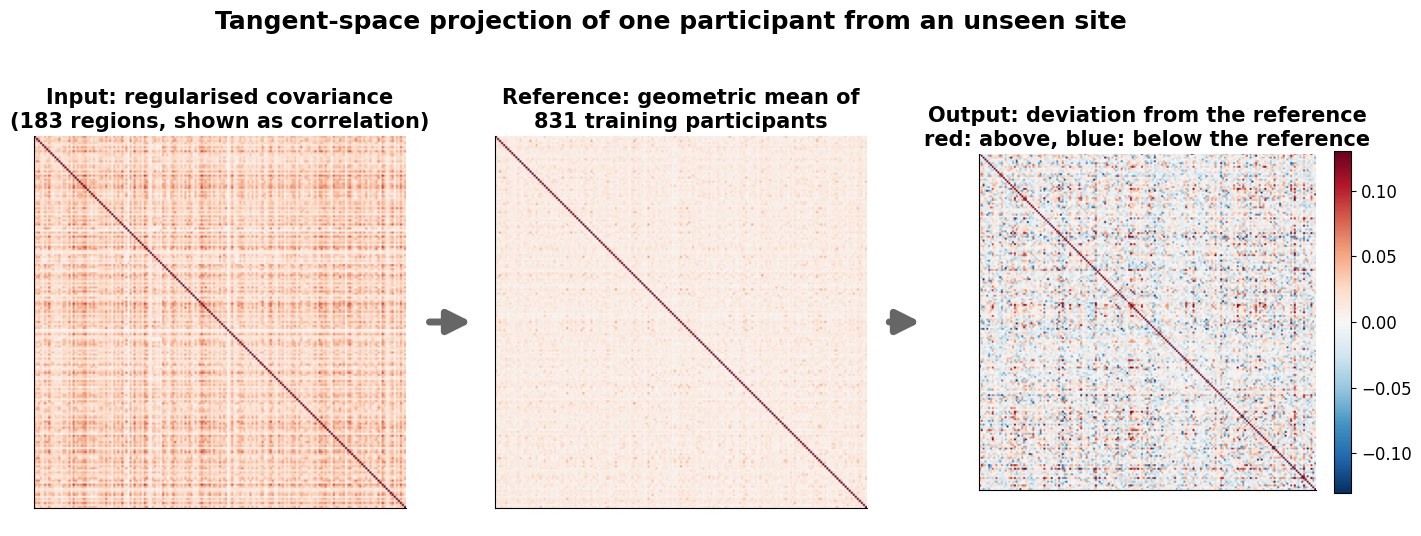

In [ ]:
# @title Figure 11. Tangent-space projection
def corr_view(M):
    d = np.sqrt(np.diag(M)); return M / np.outer(d, d)

fig, (a1, a2, a3) = ipo_figure("Tangent-space projection of one participant from an unseen site",
                               widths=(1, 1, 1), height=6.0)
a1.imshow(corr_view(D_Cte[ex_pos]), cmap="RdBu_r", vmin=-1, vmax=1)
a1.set_title(f"Input: regularised covariance\n({int(D_keep.sum())} regions, shown as correlation)")
a2.imshow(corr_view(D_ref), cmap="RdBu_r", vmin=-1, vmax=1)
a2.set_title(f"Reference: geometric mean of\n{len(demo_tr)} training participants")
v = np.percentile(np.abs(D_T_ex), 99)
im3 = a3.imshow(D_T_ex, cmap="RdBu_r", vmin=-v, vmax=v)
a3.set_title("Output: deviation from the reference\nred: above, blue: below the reference")
plt.colorbar(im3, ax=a3, fraction=0.046)
for ax in (a1, a2, a3): ax.set_xticks([]); ax.set_yticks([])
show_save(fig, "fig11_tangent_projection")

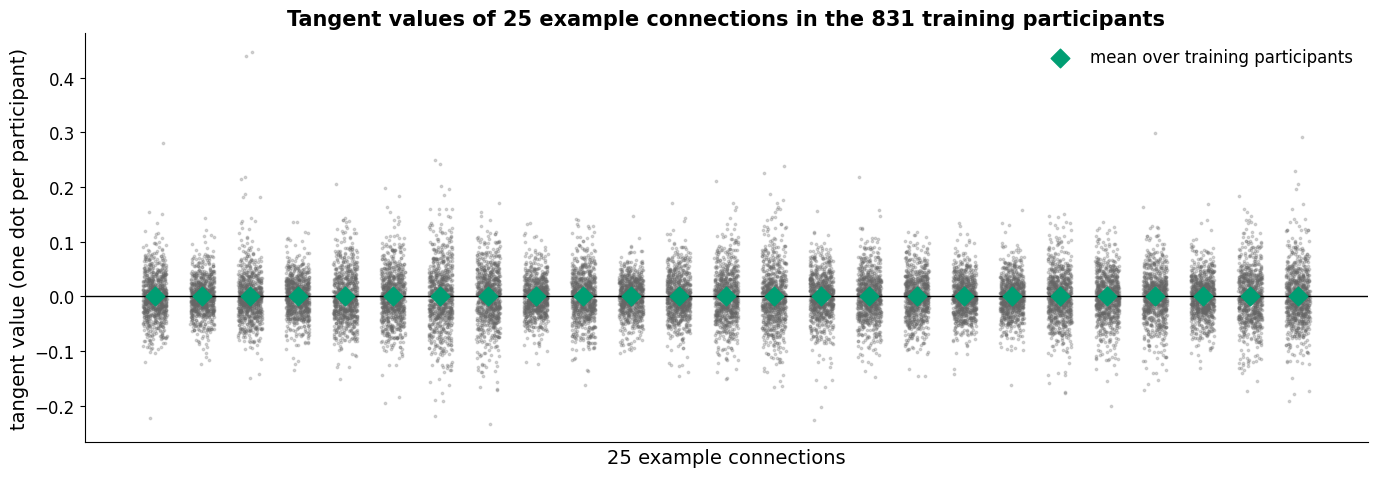

In [ ]:
# @title Figure 12. Tangent values of the training participants
fig, ax = plt.subplots(figsize=(14, 5.0))
rng_pick = np.random.default_rng(1)
tri_r, tri_c = np.tril_indices(int(D_keep.sum()))
pick = np.sort(rng_pick.choice(np.where(tri_r != tri_c)[0], 25, replace=False))
for k, f in enumerate(pick):
    ax.scatter(k + rng_pick.uniform(-0.25, 0.25, len(demo_tr)), D_Xtr[:, f], s=3, color=COL["grey"], alpha=0.25)
ax.scatter(np.arange(len(pick)), D_Xtr[:, pick].mean(0), s=90, marker="D", color=COL["green"],
           zorder=3, label="mean over training participants")
ax.axhline(0, color="black", lw=1)
ax.set_xticks([]); ax.set_xlabel("25 example connections")
ax.set_ylabel("tangent value (one dot per participant)"); ax.legend(frameon=False, loc="upper right")
ax.set_title(f"Tangent values of 25 example connections in the {len(demo_tr)} training participants")
fig.tight_layout()
show_save(fig, "fig12_tangent_centring")

# 7. Feature vectors

### 7.1 Vectorisation
**Input:** one deviation matrix per participant. **Output:** one row of numbers per participant, stacked into a feature table.

The classifier needs each participant as one row of numbers, with each column meaning the same value for everyone. The matrix is symmetric, so only its lower triangle including the diagonal is kept; the upper triangle is a mirror copy (Figure 13). With 179 regions this gives 179 × 180 / 2 = 16,110 values: 179 diagonal values and 15,931 connections. Stacking the rows of all participants gives the feature table.

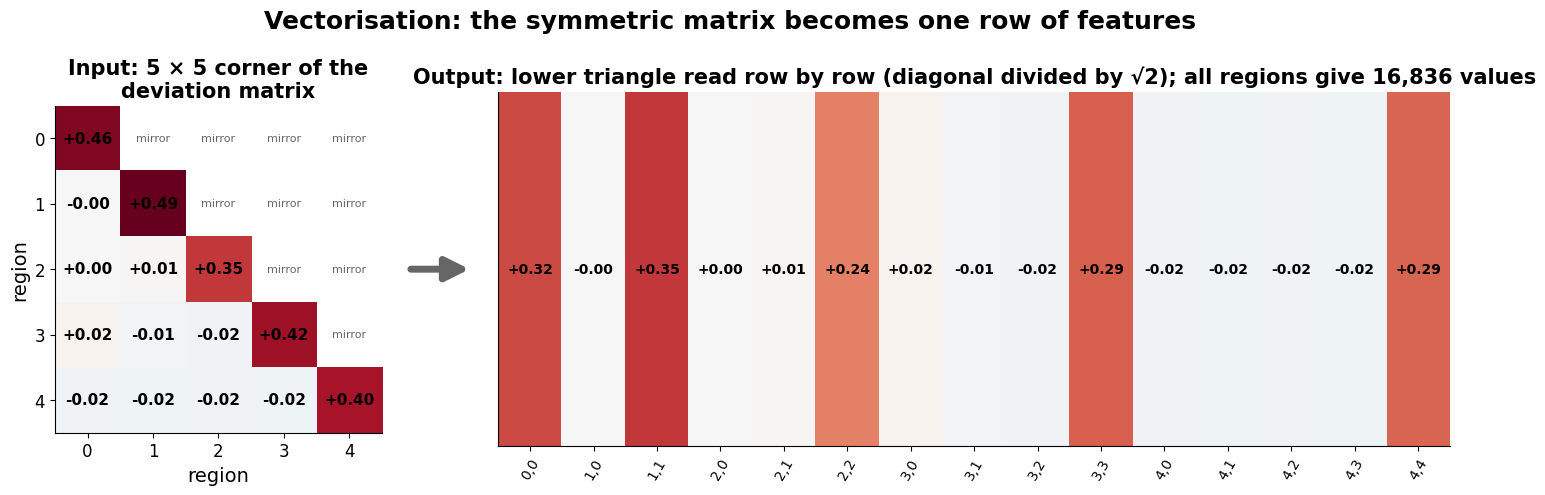

In [ ]:
# @title Figure 13. Vectorisation
k5 = 5
blk = D_T_ex[:k5, :k5]
rows_, cols_ = np.tril_indices(k5)
vals = blk[rows_, cols_] / np.where(rows_ == cols_, np.sqrt(2), 1)

fig = plt.figure(figsize=(18, 4.6))
gs = GridSpec(1, 3, figure=fig, width_ratios=[0.55, 0.12, 1.6], wspace=0.05)
a1 = fig.add_subplot(gs[0]); aa = fig.add_subplot(gs[1]); a2 = fig.add_subplot(gs[2])
v = np.abs(blk).max()
a1.imshow(np.where(np.triu(np.ones((k5, k5), bool), 1), np.nan, blk), cmap="RdBu_r", vmin=-v, vmax=v)
for i in range(k5):
    for j in range(k5):
        if j <= i:
            a1.text(j, i, f"{blk[i, j]:+.2f}", ha="center", va="center", fontsize=11, weight="bold")
        else:
            a1.text(j, i, "mirror", ha="center", va="center", fontsize=8, color=COL["grey"])
a1.set_xticks(range(k5)); a1.set_yticks(range(k5)); a1.set_xlabel("region"); a1.set_ylabel("region")
a1.set_title("Input: 5 × 5 corner of the\ndeviation matrix")
aa.axis("off"); aa.annotate("", xy=(0.95, 0.5), xytext=(0.05, 0.5), xycoords="axes fraction",
                            arrowprops=dict(arrowstyle="-|>", lw=5, color=COL["grey"], mutation_scale=35))
a2.imshow(vals[None, :], cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
for k, val in enumerate(vals):
    a2.text(k, 0, f"{val:+.2f}", ha="center", va="center", fontsize=10, weight="bold")
a2.set_yticks([]); a2.set_xticks(range(len(vals)))
a2.set_xticklabels([f"{i},{j}" for i, j in zip(rows_, cols_)], rotation=60, fontsize=10)
a2.set_title(f"Output: lower triangle read row by row (diagonal divided by √2); all regions give {D_Xtr.shape[1]:,} values")
fig.suptitle("Vectorisation: the symmetric matrix becomes one row of features", y=1.06)
show_save(fig, "fig13_vectorisation")

In [ ]:
# 7.1 The feature table of the worked-example round
kidx = np.where(D_keep)[0]                                   # original region numbers kept in this round
fr, fc = np.tril_indices(len(kidx))
feature_names = [f"{kidx[i]}-{kidx[j]}" for i, j in zip(fr, fc)]
print(f"training feature table: {D_Xtr.shape[0]} rows (training participants) × {D_Xtr.shape[1]:,} columns (features)")
print("each column name gives the two regions of the value; equal numbers mark a diagonal value")
display(pd.DataFrame(D_Xtr[:5, :8], columns=feature_names[:8],
                     index=pd.Index(sub_id[demo_tr[:5]], name="participant")).round(3))

training feature table: 831 rows (training participants) × 16,836 columns (features)
each column name gives the two regions of the value; equal numbers mark a diagonal value


,0-0,1-0,1-1,2-0,2-1,2-2,3-0,3-1
participant,,,,,,,,
50003,0.635,0.009,0.467,0.043,0.005,0.531,-0.016,-0.029
50004,-0.742,0.025,-0.533,-0.002,-0.047,-0.614,-0.012,-0.038
50005,-0.219,-0.001,-0.152,0.006,-0.019,-0.232,0.010,0.024
50006,-0.601,-0.043,-0.426,-0.017,-0.067,-0.534,0.012,0.034
50007,0.246,0.011,0.329,-0.006,-0.075,0.329,0.004,0.004


### 7.2 Standardisation
**Input:** the feature table. **Output:** the same table with every column rescaled.

Each feature is rescaled to mean 0 and standard deviation 1, using the training participants only:
```
feature A    100    200    300      becomes    -1.22    0    +1.22
feature B    0.1    0.2    0.3      becomes    -1.22    0    +1.22
```
Without this, features with small values would need large weights and be penalised more heavily by the regularisation in section 8. Test participants are rescaled with the training mean and standard deviation, so they do not influence it.

In Figure 14 (left), the dark vertical stripes are the diagonal values, which vary about ten times more than connection values (middle panel); standardisation puts all features on the same scale.

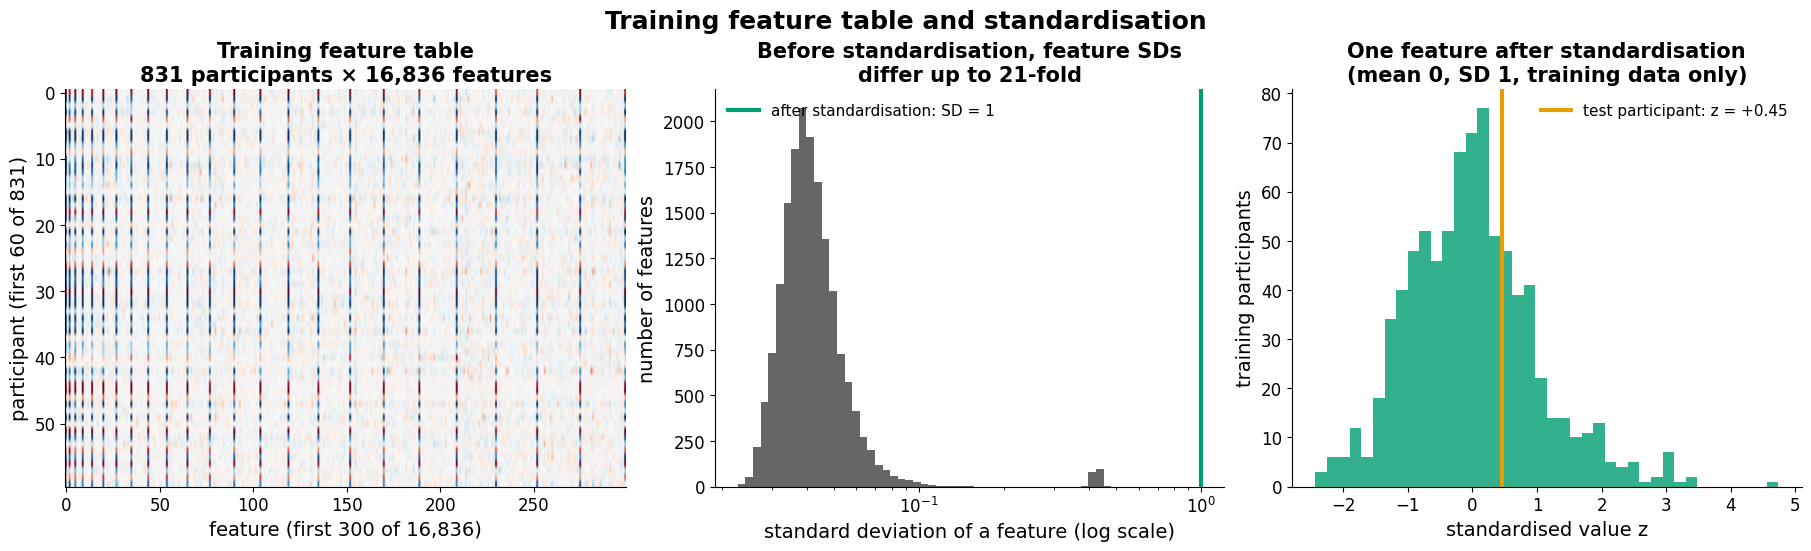

In [ ]:
# @title Figure 14. Training feature table and standardisation
sc_demo = StandardScaler().fit(D_Xtr)
col = int(np.argmax(D_Xtr.std(0)))
sds = D_Xtr.std(0)
fig, axs = plt.subplots(1, 3, figsize=(18, 5.4), width_ratios=[1.1, 1, 1], layout="constrained")
show = D_Xtr[:60, :300]
lim = np.percentile(np.abs(show), 98)
axs[0].imshow(show, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
axs[0].set_xlabel(f"feature (first 300 of {D_Xtr.shape[1]:,})"); axs[0].set_ylabel(f"participant (first 60 of {len(demo_tr)})")
axs[0].set_title(f"Training feature table\n{len(demo_tr)} participants × {D_Xtr.shape[1]:,} features")
axs[1].hist(sds, bins=np.logspace(np.log10(sds.min()), np.log10(sds.max()), 50), color=COL["grey"])
axs[1].axvline(1.0, color=COL["green"], lw=3, label="after standardisation: SD = 1")
axs[1].set_xscale("log"); axs[1].set_xlabel("standard deviation of a feature (log scale)")
axs[1].set_ylabel("number of features"); axs[1].legend(frameon=False, loc="upper left", fontsize=11)
axs[1].set_title(f"Before standardisation, feature SDs\ndiffer up to {sds.max() / sds.min():.0f}-fold")
ztr, zte = sc_demo.transform(D_Xtr)[:, col], sc_demo.transform(D_Xte)[ex_pos, col]
axs[2].hist(ztr, bins=40, color=COL["green"], alpha=0.8)
axs[2].axvline(zte, color=COL["test"], lw=3, label=f"test participant: z = {zte:+.2f}")
axs[2].set_title("One feature after standardisation\n(mean 0, SD 1, training data only)")
axs[2].legend(frameon=False, loc="upper right", fontsize=11); axs[2].set_xlabel("standardised value z")
axs[2].set_ylabel("training participants")
fig.suptitle("Training feature table and standardisation")
show_save(fig, "fig14_standardisation")

### 7.3 One participant's features
Figure 15 summarises sections 3 to 7 for the worked-example participant. Each step takes the output of the previous one as its input; the last panel is the row of numbers the classifier receives.

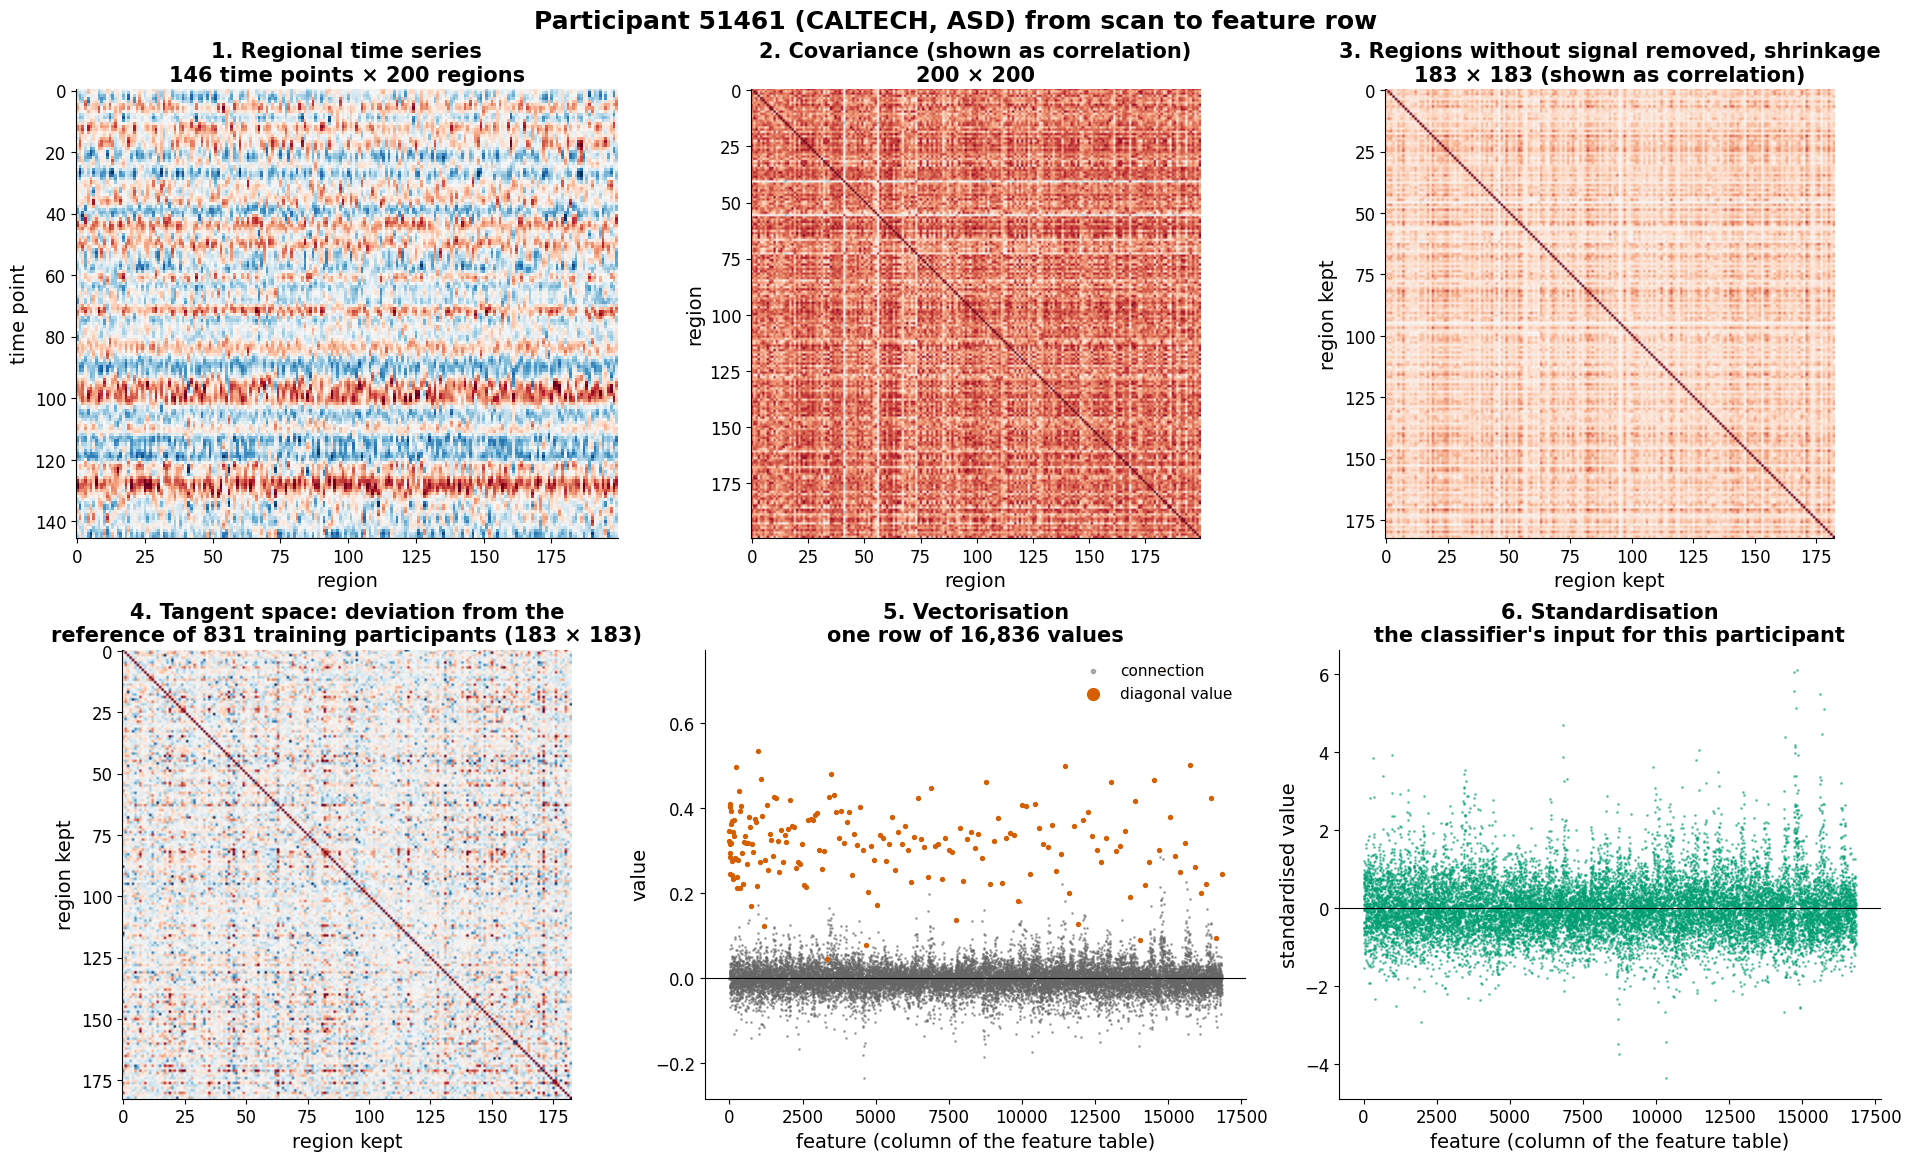

In [ ]:
# @title Figure 15. The worked-example participant at each step
X_ex = ts[EX]
sdx = X_ex.std(0)
Zx = np.where(sdx > 0, (X_ex - X_ex.mean(0)) / np.where(sdx > 0, sdx, 1), 0)
sc_ex = StandardScaler().fit(D_Xtr)
row_raw = D_Xte[ex_pos]
row_std = sc_ex.transform(D_Xte[ex_pos:ex_pos + 1])[0]
diag_pos = np.where(fr == fc)[0]
R_ = int(D_keep.sum())

fig, axs = plt.subplots(2, 3, figsize=(19, 11.5), layout="constrained")
ax = axs[0, 0]
ax.imshow(Zx, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, interpolation="nearest")
ax.set_xlabel("region"); ax.set_ylabel("time point")
ax.set_title(f"1. Regional time series\n{X_ex.shape[0]} time points × {X_ex.shape[1]} regions")
ax = axs[0, 1]
S_ex = S_full[EX]; d_ = np.sqrt(np.diag(S_ex)); ok_ = d_ > 0
Rv = np.zeros_like(S_ex); Rv[np.ix_(ok_, ok_)] = S_ex[np.ix_(ok_, ok_)] / np.outer(d_[ok_], d_[ok_])
ax.imshow(Rv, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xlabel("region"); ax.set_ylabel("region")
ax.set_title(f"2. Covariance (shown as correlation)\n{S_ex.shape[0]} × {S_ex.shape[1]}")
ax = axs[0, 2]
ax.imshow(corr_view(D_Cte[ex_pos]), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xlabel("region kept"); ax.set_ylabel("region kept")
ax.set_title(f"3. Regions without signal removed, shrinkage\n{R_} × {R_} (shown as correlation)")
ax = axs[1, 0]
vt = np.percentile(np.abs(D_T_ex), 99)
ax.imshow(D_T_ex, cmap="RdBu_r", vmin=-vt, vmax=vt)
ax.set_xlabel("region kept"); ax.set_ylabel("region kept")
ax.set_title(f"4. Tangent space: deviation from the\nreference of {len(demo_tr)} training participants ({R_} × {R_})")
ax = axs[1, 1]
ax.scatter(np.arange(len(row_raw)), row_raw, s=1, color=COL["grey"], alpha=0.5, label="connection")
ax.scatter(diag_pos, row_raw[diag_pos], s=8, color=COL["asd"], label="diagonal value")
ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("feature (column of the feature table)"); ax.set_ylabel("value")
ax.legend(frameon=True, framealpha=0.9, edgecolor="none", loc="upper right", markerscale=3, fontsize=11)
ax.set_title(f"5. Vectorisation\none row of {len(row_raw):,} values")
ax = axs[1, 2]
ax.scatter(np.arange(len(row_std)), row_std, s=1, color=COL["green"], alpha=0.5)
ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("feature (column of the feature table)"); ax.set_ylabel("standardised value")
ax.set_title(f"6. Standardisation\nthe classifier's input for this participant")
fig.suptitle(f"Participant {sub_id[EX]} ({site[EX]}, {'ASD' if y[EX] else 'control'}) from scan to feature row")
show_save(fig, "fig15_participant_steps")

# 8. Classification and evaluation

### 8.1 Logistic regression with L2 regularisation
**Input:** the standardised feature table of the training sites and their diagnoses. **Output:** a predicted probability of ASD for every test participant.

Logistic regression gives every feature a weight, adds up the weighted features into a score and turns the score into a probability between 0 and 1 with an S-shaped curve, on which a score of 0 gives 0.5. A probability above 0.5 is classified as ASD. A toy example with three features:
```
feature values    +1.0    -0.5    +2.0
weights           +0.4    -0.2    +0.1        intercept -0.1
score             0.40 + 0.10 + 0.20 - 0.10 = 0.60          probability of ASD 0.65
```
Training adjusts the weights so that training participants with ASD receive high probabilities and controls low ones.

With 674 to 835 training participants and about 16,000 features, an unconstrained model would memorise the training data. L2 regularisation penalises large weights, so the model prefers many small weights to a few large ones. The parameter C sets the strength: a smaller C means stronger regularisation. L2-regularised linear models performed best in both Abraham et al. (2017) and Dadi et al. (2019). Class weights are inversely proportional to group size, so the larger control group does not dominate training. A single weight does not show how important its connection is, because the features are correlated (section 13).

### 8.2 Leave-one-site-out cross-validation
In each of the 19 rounds, one site is held out. Region removal, the reference matrix, standardisation, C and the model weights are all derived from the remaining 18 sites, and the held-out site is then predicted. After 19 rounds, each participant has exactly one prediction from a model that never saw their site (Figure 16, left).

### 8.3 Selection of the regularisation strength
C is chosen within each round from the training sites only (Figure 16, right):
* the 18 training sites are divided into four groups of whole sites
* each of nine C values is trained on three groups and evaluated on the fourth, rotating until every group has been evaluated once
* the C with the highest mean AUC is used to train the final model of the round

Choosing C on the test site would bias performance upward (Varma & Simon, 2006; Varoquaux et al., 2017). Grouping by site makes this inner evaluation match the outer one: performance on unseen sites.

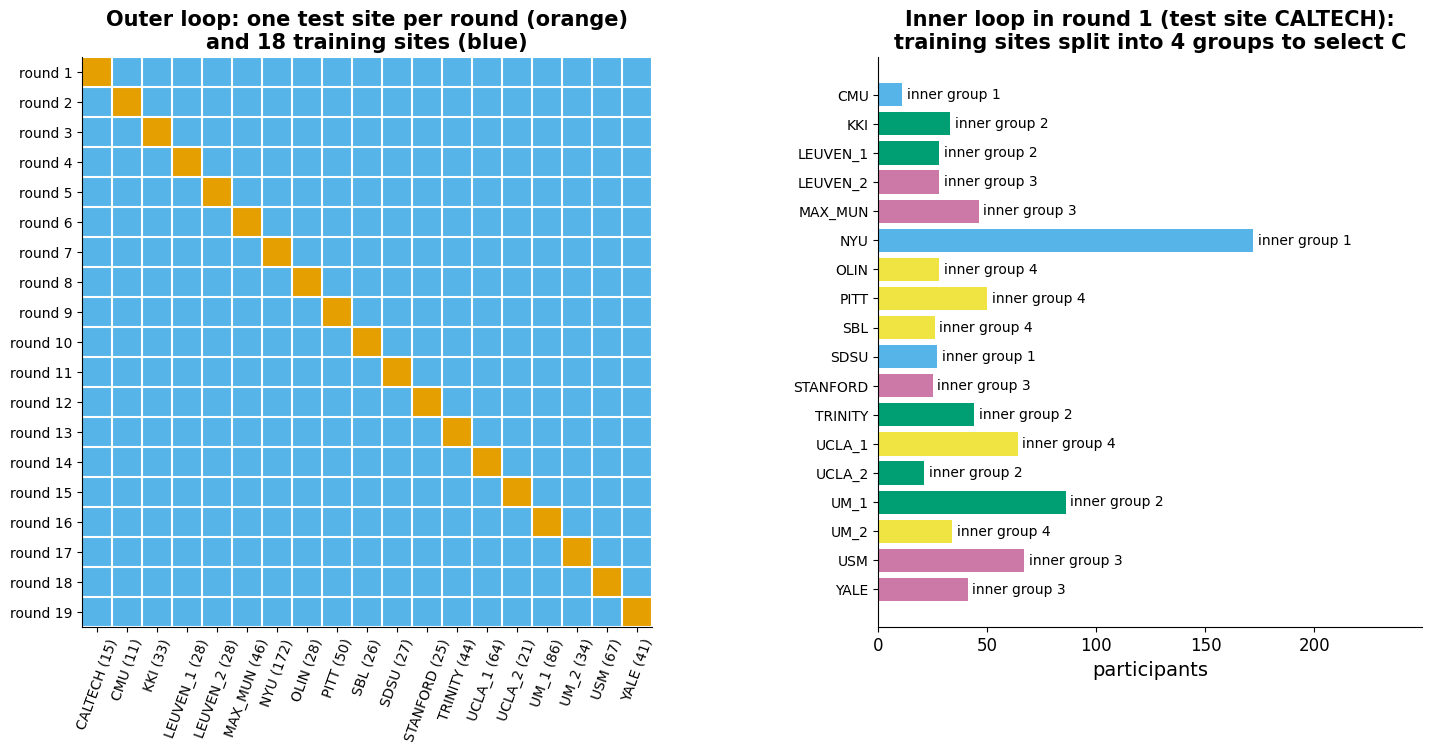

In [ ]:
# @title Figure 16. Cross-validation design
n_site = np.array([len(IDX[s]) for s in SITES])
grid = np.ones((len(SITES), len(SITES)))
np.fill_diagonal(grid, 2)
fig = plt.figure(figsize=(18, 7.4))
gs = GridSpec(1, 2, figure=fig, width_ratios=[1.25, 1], wspace=0.28)
ax = fig.add_subplot(gs[0])
ax.imshow(grid, cmap=matplotlib.colors.ListedColormap([COL["train"], COL["test"]]), vmin=1, vmax=2)
ax.set_xticks(range(len(SITES))); ax.set_xticklabels([f"{s} ({n})" for s, n in zip(SITES, n_site)], rotation=70, fontsize=10)
ax.set_yticks(range(len(SITES))); ax.set_yticklabels([f"round {k + 1}" for k in range(len(SITES))], fontsize=10)
ax.set_xticks(np.arange(-.5, len(SITES)), minor=True); ax.set_yticks(np.arange(-.5, len(SITES)), minor=True)
ax.grid(which="minor", color="white", lw=1.5); ax.tick_params(which="minor", length=0)
ax.set_title("Outer loop: one test site per round (orange)\nand 18 training sites (blue)")

ax = fig.add_subplot(gs[1])
tr0 = np.where(site != SITES[0])[0]
inner_of = {}
for g, (_, b_) in enumerate(GroupKFold(n_splits=CONFIG["inner_folds"]).split(tr0, y[tr0], groups=site[tr0])):
    for s in np.unique(site[tr0][b_]):
        inner_of[s] = g
tr_sites = [s for s in SITES if s != SITES[0]]
cols4 = ["#56B4E9", "#009E73", "#CC79A7", "#F0E442"]
for k, s in enumerate(tr_sites):
    ax.barh(k, len(IDX[s]), color=cols4[inner_of[s]])
    ax.text(len(IDX[s]) + 2, k, f"inner group {inner_of[s] + 1}", va="center", fontsize=10)
ax.set_yticks(range(len(tr_sites))); ax.set_yticklabels(tr_sites, fontsize=10); ax.invert_yaxis()
ax.set_xlabel("participants"); ax.set_xlim(0, n_site.max() * 1.45)
ax.set_title(f"Inner loop in round 1 (test site {SITES[0]}):\ntraining sites split into 4 groups to select C")
show_save(fig, "fig16_cross_validation_design")

In [ ]:
# 8.3 Training functions: nested selection of C and the leave-one-site-out loop
def fit_lr(X, yy, C):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return LogisticRegression(C=C, max_iter=2000, class_weight="balanced").fit(X, yy)

def tune_and_fit(Ztr, ytr, Zte, groups_tr):
    # select C by inner cross-validation grouped by site, then refit on all training participants
    gkf = GroupKFold(n_splits=min(CONFIG["inner_folds"], len(np.unique(groups_tr))))
    splits = [(a, b) for a, b in gkf.split(Ztr, ytr, groups=groups_tr)
              if len(np.unique(ytr[a])) > 1 and len(np.unique(ytr[b])) > 1]
    scores = np.full(len(C_GRID), np.nan)
    for k, C in enumerate(C_GRID):
        s = [roc_auc_score(ytr[b], fit_lr(Ztr[a], ytr[a], C).decision_function(Ztr[b])) for a, b in splits]
        if s:
            scores[k] = np.mean(s)
    best_C = float(C_GRID[len(C_GRID) // 2]) if np.isnan(scores).all() else float(C_GRID[np.nanargmax(scores)])
    model = fit_lr(Ztr, ytr, best_C)
    return model.predict_proba(Zte)[:, 1], best_C, scores, model

PERM_CACHE = DIRS["05_checks"] / "permutation_cache"

def run_loso(mode, tag, keep_weights):
    # one leave-one-site-out run; every round is saved separately, so an interruption loses at most one round
    out = DIRS["03_model"] / tag
    out.mkdir(parents=True, exist_ok=True)
    if keep_weights:
        PERM_CACHE.mkdir(parents=True, exist_ok=True)
    def finished(s):
        return (out / f"round_{s}.npz").exists() and (not keep_weights or (PERM_CACHE / f"round_{s}.npz").exists())
    todo = [s for s in SITES if not finished(s)]
    if todo:
        log(f"[{tag}] {len(SITES) - len(todo)} of 19 rounds already saved, running {len(todo)}")
    else:
        log(f"[{tag}] all 19 rounds were trained in an earlier run and are loaded from Drive")
    t_start = time.time()
    for k, s in enumerate(todo):
        t0 = time.time()
        tr, te = np.where(site != s)[0], IDX[s]
        Xtr, Xte, info = build_fold_features(tr, te, mode)
        sc = StandardScaler().fit(Xtr)
        Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)
        prob, C, scores, model = tune_and_fit(Ztr, y[tr], Zte, site[tr])
        payload = dict(te=te, prob=prob, C=C, inner_auc=scores, keep=info["keep"],
                       gm_iterations=info["iterations"], n_features=Xtr.shape[1])
        if keep_weights:
            payload.update(coef=model.coef_[0].astype(np.float32), intercept=model.intercept_,
                           scaler_mean=sc.mean_.astype(np.float32), scaler_scale=sc.scale_.astype(np.float32))
            # label-free compressed features, used only by the permutation test (section 10.1)
            U, sv, Vt = np.linalg.svd(Ztr, full_matrices=False)
            save_npz(PERM_CACHE / f"round_{s}.npz", Rtr=U * sv, Rte=Zte @ Vt.T, tr=tr, te=te)
            del U, sv, Vt
        save_npz(out / f"round_{s}.npz", **payload)
        del Xtr, Xte, Ztr, Zte, info
        gc.collect()
        rate = (time.time() - t_start) / (k + 1)
        log(f"[{tag}] {s:9s} n={len(te):3d}  C={C:.1e}  balanced accuracy {ba(y[te], prob):.3f}  "
            f"({time.time() - t0:.0f} s, about {rate * (len(todo) - k - 1) / 60:.0f} min remaining)")
    prob_all, C_of, inner, rows = np.full(N, np.nan), {}, {}, []
    for s in SITES:
        z = np.load(out / f"round_{s}.npz")
        prob_all[z["te"]] = z["prob"]; C_of[s] = float(z["C"]); inner[s] = z["inner_auc"]
        i = z["te"]
        rows.append({"test site": s, "n": len(i), "ASD": int(y[i].sum()), "control": int((y[i] == 0).sum()),
                     "regions": int(z["keep"].sum()), "features": int(z["n_features"]), "selected C": f"{C_of[s]:.1e}",
                     "best inner AUC": float(np.nanmax(z["inner_auc"])), "balanced accuracy": ba(y[i], z["prob"]),
                     "AUC": roc_auc_score(y[i], z["prob"]), "round": "trained now" if s in todo else "loaded"})
    assert np.isfinite(prob_all).all(), "some participants have no prediction"
    print(f"\n[{tag}] one row per round: a model trained on the other 18 sites and tested on this site")
    print(pd.DataFrame(rows).round(3).to_string(index=False))
    pd.DataFrame({"sub_id": sub_id, "site": site, "dx": np.where(y == 1, "ASD", "control"),
                  "prob_asd": prob_all, "predicted": np.where(prob_all > 0.5, "ASD", "control"),
                  "C_of_round": [C_of[s] for s in site]}).to_csv(DIRS["03_model"] / f"predictions_{tag}.csv", index=False)
    return prob_all, C_of, inner

print("training functions defined")

training functions defined


### 8.4 One training round, step by step
Each of the 19 rounds runs the same five steps. This section runs them in full for one round, with CALTECH as the unseen test site, so every step and its output can be seen. The input is the feature tables built in section 6.4: one row per participant, one column per feature.

1. **Input:** the training table (18 sites) and the test table (CALTECH).
2. **Standardisation** with the training participants only (section 7.2).
3. **Choice of C** by inner cross-validation: the 18 training sites are split into four groups of whole sites, and each of the nine C values is trained on three groups and scored on the fourth.
4. **Final model:** the best C is used to train one model on all training participants.
5. **Prediction:** the model gives each CALTECH participant a probability of ASD, which is then scored.

This repeats the round already saved by the main model (section 8.5), so the last line checks that the two agree. It takes about 2 minutes.

In [ ]:
# 8.4 One complete training round, step by step (test site CALTECH, about 2 minutes)

# Step 1. Input: feature tables of the worked-example round (section 6.4)
Xtr_demo, Xte_demo = D_Xtr.astype(np.float64), D_Xte.astype(np.float64)
ytr_demo, yte_demo = y[demo_tr], y[demo_te]
print(f"Step 1. Training table: {Xtr_demo.shape[0]} participants × {Xtr_demo.shape[1]:,} features "
      f"({ytr_demo.sum()} ASD, {(ytr_demo == 0).sum()} control) from {len(np.unique(site[demo_tr]))} sites")
print(f"        Test table: {Xte_demo.shape[0]} participants from {DEMO} ({yte_demo.sum()} ASD, {(yte_demo == 0).sum()} control)")

# Step 2. Standardise every feature with the training mean and standard deviation
scaler_demo = StandardScaler().fit(Xtr_demo)
Ztr_demo, Zte_demo = scaler_demo.transform(Xtr_demo), scaler_demo.transform(Xte_demo)
print(f"\nStep 2. After standardisation, every training feature has mean 0 and SD 1 "
      f"(largest deviation from 0: {np.abs(Ztr_demo.mean(0)).max():.1e}; SD range {Ztr_demo.std(0).min():.3f} to {Ztr_demo.std(0).max():.3f})")

# Step 3. Choose C by inner cross-validation over the training sites
inner_splits = [(a, b) for a, b in GroupKFold(n_splits=CONFIG["inner_folds"]).split(Ztr_demo, ytr_demo, groups=site[demo_tr])
                if len(np.unique(ytr_demo[a])) > 1 and len(np.unique(ytr_demo[b])) > 1]
print("\nStep 3. Inner groups of training sites:")
for k, (a, b) in enumerate(inner_splits):
    print(f"        group {k + 1}: {', '.join(sorted(np.unique(site[demo_tr][b])))} ({len(b)} participants)")
inner_demo = []
for C in C_GRID:
    aucs = [roc_auc_score(ytr_demo[b], fit_lr(Ztr_demo[a], ytr_demo[a], C).decision_function(Ztr_demo[b]))
            for a, b in inner_splits]
    inner_demo.append(np.mean(aucs))
    print(f"        C = {C:.1e}: AUC on each held-out group " + "  ".join(f"{v:.3f}" for v in aucs)
          + f"  | mean {np.mean(aucs):.3f}")
C_demo = float(C_GRID[int(np.argmax(inner_demo))])
print(f"        selected C = {C_demo:.1e} (highest mean inner AUC, {max(inner_demo):.3f})")

# Step 4. Train the final model of this round on all training participants
model_demo = fit_lr(Ztr_demo, ytr_demo, C_demo)
w_demo = model_demo.coef_[0]
print(f"\nStep 4. Final model: {len(w_demo):,} weights (one per feature) and an intercept of {model_demo.intercept_[0]:+.3f}; "
      f"weights range from {w_demo.min():+.4f} to {w_demo.max():+.4f}")

# Step 5. Predict the unseen site and score the predictions
prob_demo = model_demo.predict_proba(Zte_demo)[:, 1]
pred_tab = pd.DataFrame({"participant": sub_id[demo_te], "diagnosis": np.where(yte_demo == 1, "ASD", "control"),
                         "score": model_demo.decision_function(Zte_demo), "probability of ASD": prob_demo,
                         "predicted": np.where(prob_demo > 0.5, "ASD", "control")})
pred_tab["correct"] = pred_tab["diagnosis"] == pred_tab["predicted"]
print(f"\nStep 5. Predictions for the {len(demo_te)} {DEMO} participants (score turned into a probability; above 0.5 means ASD):")
print(pred_tab.sort_values("probability of ASD", ascending=False).round(3).to_string(index=False))
print(f"        balanced accuracy {ba(yte_demo, prob_demo):.3f}, AUC {roc_auc_score(yte_demo, prob_demo):.3f}")

saved_demo = np.load(DIRS["03_model"] / "main_kappa100" / f"round_{DEMO}.npz")
print(f"\nCheck against the saved {DEMO} round of the main model: same C {np.isclose(float(saved_demo['C']), C_demo)}, "
      f"largest difference in probability {np.abs(saved_demo['prob'] - prob_demo).max():.4f}")

Step 1. Training table: 831 participants × 16,836 features (386 ASD, 445 control) from 18 sites
        Test table: 15 participants from CALTECH (5 ASD, 10 control)

Step 2. After standardisation, every training feature has mean 0 and SD 1 (largest deviation from 0: 2.8e-16; SD range 1.000 to 1.000)

Step 3. Inner groups of training sites:
        group 1: CMU, NYU, SDSU (210 participants)
        group 2: KKI, LEUVEN_1, TRINITY, UCLA_2, UM_1 (212 participants)
        group 3: LEUVEN_2, MAX_MUN, STANFORD, USM, YALE (207 participants)
        group 4: OLIN, PITT, SBL, UCLA_1, UM_2 (202 participants)
        C = 1.0e-04: AUC on each held-out group 0.811  0.713  0.768  0.783  | mean 0.769
        C = 4.2e-04: AUC on each held-out group 0.813  0.717  0.775  0.789  | mean 0.773
        C = 1.8e-03: AUC on each held-out group 0.810  0.718  0.773  0.787  | mean 0.772
        C = 7.5e-03: AUC on each held-out group 0.806  0.716  0.772  0.781  | mean 0.769
        C = 3.2e-02: AUC on each held

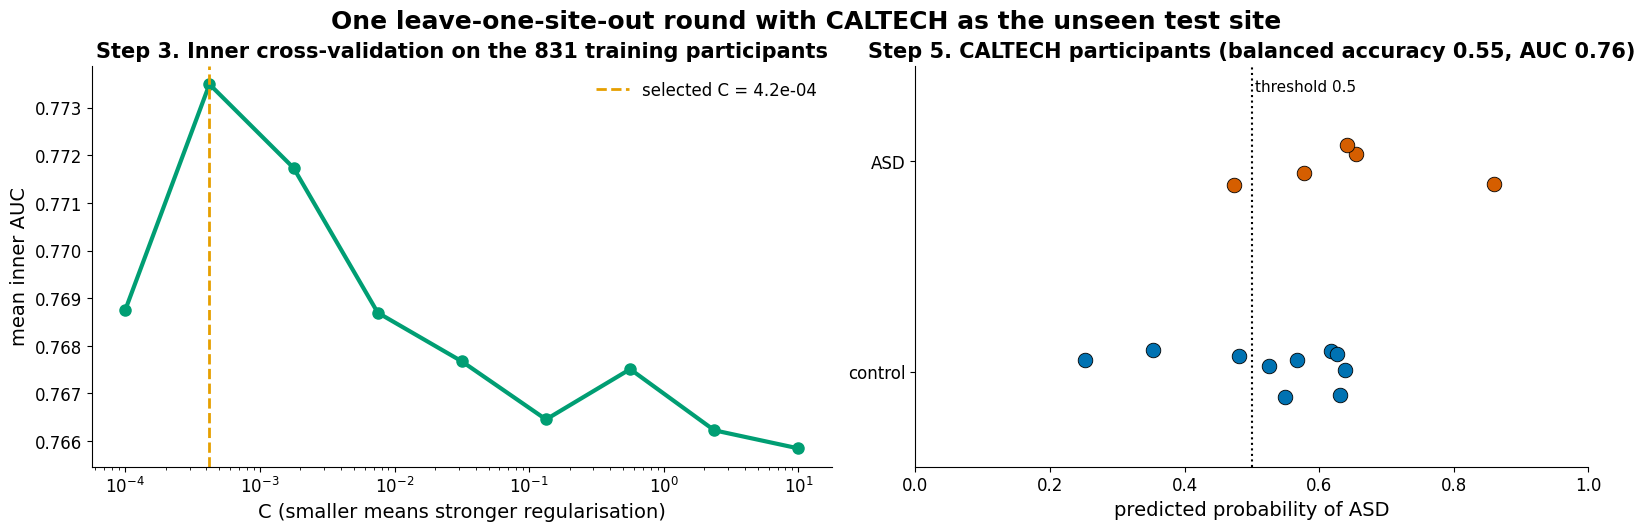

In [ ]:
# @title Figure 17. One training round: choice of C and predictions for the unseen site
fig, axs = plt.subplots(1, 2, figsize=(16, 5.2), width_ratios=[1.1, 1], layout="constrained")
ax = axs[0]
ax.semilogx(C_GRID, inner_demo, color=COL["green"], lw=3, marker="o", ms=8)
ax.axvline(C_demo, color=COL["test"], ls="--", lw=2, label=f"selected C = {C_demo:.1e}")
ax.set_xlabel("C (smaller means stronger regularisation)"); ax.set_ylabel("mean inner AUC")
ax.legend(frameon=False, loc="best"); ax.set_title(f"Step 3. Inner cross-validation on the {len(demo_tr)} training participants")
ax = axs[1]
jit = np.random.default_rng(0).uniform(-0.12, 0.12, len(demo_te))
for g, c, lab in [(0, COL["ctrl"], "control"), (1, COL["asd"], "ASD")]:
    m = yte_demo == g
    ax.scatter(prob_demo[m], g + jit[m], s=110, color=c, edgecolor="black", lw=0.6, label=lab, zorder=3)
ax.axvline(0.5, color="black", ls=":", lw=1.5); ax.text(0.505, 1.33, "threshold 0.5", fontsize=11)
ax.set_yticks([0, 1]); ax.set_yticklabels(["control", "ASD"]); ax.set_ylim(-0.45, 1.45)
ax.set_xlim(0, 1); ax.set_xlabel("predicted probability of ASD")
ax.set_title(f"Step 5. {DEMO} participants (balanced accuracy {ba(yte_demo, prob_demo):.2f}, AUC {roc_auc_score(yte_demo, prob_demo):.2f})")
fig.suptitle(f"One leave-one-site-out round with {DEMO} as the unseen test site")
show_save(fig, "fig17_training_round")

### 8.5 Main model: all 19 rounds
The same five steps are repeated with each of the 19 sites as the test site, using condition-number matching. The model weights of every round are saved for the later analysis of which connections contribute to classification.

**Output:** a table with one row per round, and one predicted probability of ASD per participant (second table).

In [ ]:
# 8.5 Main model: condition-number matching (target 100), 19 rounds
P_main, C_main, INNER_main = run_loso("cond", "main_kappa100", keep_weights=True)
log(f"main model: balanced accuracy {ba(y, P_main):.3f}, AUC {roc_auc_score(y, P_main):.3f}")

2026-10-20 18:11:16  [main_kappa100] all 19 rounds were trained in an earlier run and are loaded from Drive

[main_kappa100] one row per round: a model trained on the other 18 sites and tested on this site
test site   n  ASD  control  regions  features selected C  best inner AUC  balanced accuracy   AUC  round
  CALTECH  15    5       10      183     16836    4.2e-04           0.773              0.550 0.760 loaded
      CMU  11    6        5      180     16290    4.2e-04           0.775              0.750 0.833 loaded
      KKI  33   12       21      179     16110    4.2e-04           0.762              0.643 0.778 loaded
 LEUVEN_1  28   14       14      179     16110    1.8e-03           0.769              0.643 0.633 loaded
 LEUVEN_2  28   12       16      179     16110    4.2e-04           0.755              0.719 0.875 loaded
  MAX_MUN  46   19       27      179     16110    4.2e-04           0.763              0.567 0.559 loaded
      NYU 172   74       98      179     16110    1.

In [ ]:
# 8.5 Output: the predictions table
PRED = pd.read_csv(DIRS["03_model"] / "predictions_main_kappa100.csv", dtype={"sub_id": str})
print(f"predictions table: {len(PRED)} rows (one per participant); first 5 rows")
display(PRED.head().round(3))
print(f"worked-example participant {sub_id[EX]} ({'ASD' if y[EX] else 'control'}): "
      f"predicted probability of ASD {P_main[EX]:.3f}")

predictions table: 846 rows (one per participant); first 5 rows


,sub_id,site,dx,prob_asd,predicted,C_of_round
0,50003,PITT,ASD,0.517,ASD,0.0
1,50004,PITT,ASD,0.580,ASD,0.0
2,50005,PITT,ASD,0.444,control,0.0
3,50006,PITT,ASD,0.688,ASD,0.0
4,50007,PITT,ASD,0.550,ASD,0.0


worked-example participant 51461 (ASD): predicted probability of ASD 0.655


### 8.6 Comparison model: Ledoit-Wolf shrinkage


Identical to the main model except for the shrinkage rule (section 5.3). It reproduces the approach of Abraham et al. (2017) within this pipeline and shows whether the change of shrinkage rule affects performance (section 9.4).

In [ ]:
# 8.6 Comparison model: Ledoit-Wolf shrinkage, 19 rounds
P_lw, C_lw, INNER_lw = run_loso("lw", "comparison_ledoitwolf", keep_weights=False)
log(f"Ledoit-Wolf model: balanced accuracy {ba(y, P_lw):.3f}, AUC {roc_auc_score(y, P_lw):.3f}")

2026-10-20 18:11:23  [comparison_ledoitwolf] all 19 rounds were trained in an earlier run and are loaded from Drive

[comparison_ledoitwolf] one row per round: a model trained on the other 18 sites and tested on this site
test site   n  ASD  control  regions  features selected C  best inner AUC  balanced accuracy   AUC  round
  CALTECH  15    5       10      183     16836    5.6e-01           0.761              0.550 0.760 loaded
      CMU  11    6        5      180     16290    5.6e-01           0.764              0.750 0.667 loaded
      KKI  33   12       21      179     16110    1.8e-03           0.748              0.619 0.778 loaded
 LEUVEN_1  28   14       14      179     16110    3.2e-02           0.760              0.571 0.546 loaded
 LEUVEN_2  28   12       16      179     16110    1.8e-03           0.741              0.719 0.844 loaded
  MAX_MUN  46   19       27      179     16110    1.8e-03           0.753              0.359 0.472 loaded
      NYU 172   74       98      179

# 9. Results

### 9.1 Performance metrics
* **Balanced accuracy** is the mean of sensitivity (the proportion of ASD participants classified correctly) and specificity (the proportion of controls classified correctly). Chance is 0.5 whatever the group sizes (Brodersen et al., 2010). A model that labels everyone as control reaches a plain accuracy of 455 / 846 = 0.54, but a balanced accuracy of (0 + 1) / 2 = 0.5.
* **AUC** is the probability that a randomly chosen ASD participant receives a higher predicted probability than a randomly chosen control (Fawcett, 2006). It measures how well the model ranks participants and does not depend on the 0.5 threshold. Chance is 0.5. A toy example:
```
ASD scores 0.8, 0.4        control scores 0.6, 0.2
pairs   0.8 > 0.6 yes    0.8 > 0.2 yes    0.4 > 0.6 no    0.4 > 0.2 yes        AUC = 3 / 4 = 0.75
```
* **Pooled scores** use all 846 predictions together. **Site scores** use one site's participants only; with 11 to 172 participants per site they are uncertain (Varoquaux, 2018).

In [ ]:
# 9.1 Performance of both models, overall and per site
def summarise(prob, name):
    per_ba = [ba(y[IDX[s]], prob[IDX[s]]) for s in SITES]
    per_auc = [roc_auc_score(y[IDX[s]], prob[IDX[s]]) for s in SITES]
    pred = (prob > 0.5).astype(int)
    return {"model": name, "balanced_accuracy": ba(y, prob), "AUC": roc_auc_score(y, prob),
            "accuracy": float((pred == y).mean()), "sensitivity": float(pred[y == 1].mean()),
            "specificity": float(1 - pred[y == 0].mean()), "mean_site_balanced_accuracy": float(np.mean(per_ba)),
            "mean_site_AUC": float(np.mean(per_auc)), "lowest_site_balanced_accuracy": float(np.min(per_ba)),
            "lowest_site": SITES[int(np.argmin(per_ba))]}

def per_site(prob):
    rows = []
    for s in SITES:
        i = IDX[s]; pred = (prob[i] > 0.5).astype(int)
        rows.append({"site": s, "n": len(i), "ASD": int(y[i].sum()), "control": int((y[i] == 0).sum()),
                     "median_age": float(np.nanmedian(age[i])), "median_timepoints": int(np.median(T_sub[i])),
                     "balanced_accuracy": ba(y[i], prob[i]),
                     "AUC": roc_auc_score(y[i], prob[i]), "sensitivity": float(pred[y[i] == 1].mean()),
                     "specificity": float(1 - pred[y[i] == 0].mean())})
    return pd.DataFrame(rows)

RES = pd.DataFrame([summarise(P_main, "main (condition-number matching)"),
                    summarise(P_lw, "comparison (Ledoit-Wolf)")])
PS = per_site(P_main)
RES.to_csv(DIRS["04_results"] / "summary.csv", index=False)
PS.to_csv(DIRS["04_results"] / "per_site_main.csv", index=False)
per_site(P_lw).to_csv(DIRS["04_results"] / "per_site_ledoitwolf.csv", index=False)
print(RES.round(3).T.to_string(header=False))
print("\nPer site, main model:")
print(PS.round(3).to_string(index=False))

model                          main (condition-number matching)  comparison (Ledoit-Wolf)
balanced_accuracy                                         0.691                      0.67
AUC                                                       0.747                     0.718
accuracy                                                  0.694                     0.671
sensitivity                                                0.65                     0.645
specificity                                               0.732                     0.695
mean_site_balanced_accuracy                               0.673                     0.654
mean_site_AUC                                             0.761                     0.736
lowest_site_balanced_accuracy                              0.55                     0.359
lowest_site                                             CALTECH                   MAX_MUN

Per site, main model:
    site   n  ASD  control  median_age  median_timepoints  balanced_accuracy 

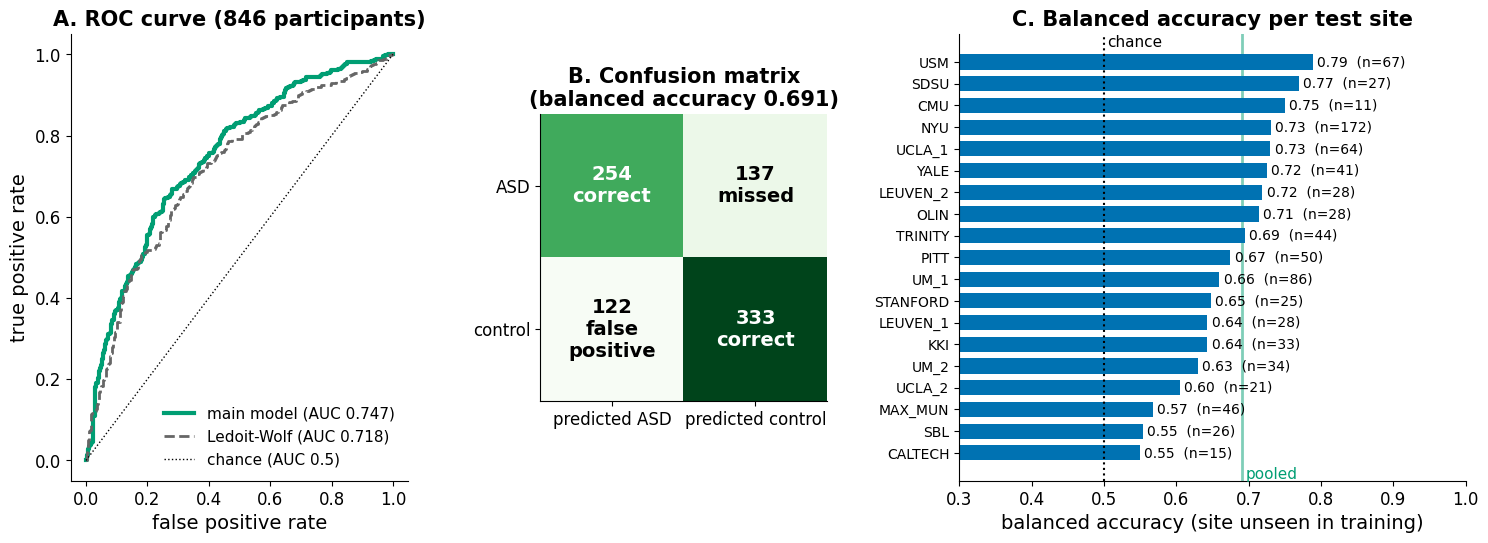

In [ ]:
# @title Figure 18. Classification performance
fig = plt.figure(figsize=(18, 5.8))
gs = GridSpec(1, 3, figure=fig, width_ratios=[1, 0.85, 1.5], wspace=0.35)
ax = fig.add_subplot(gs[0])
fpr, tpr, _ = roc_curve(y, P_main)
ax.plot(fpr, tpr, color=COL["green"], lw=3, label=f"main model (AUC {roc_auc_score(y, P_main):.3f})")
fpr2, tpr2, _ = roc_curve(y, P_lw)
ax.plot(fpr2, tpr2, color=COL["grey"], lw=2, ls="--", label=f"Ledoit-Wolf (AUC {roc_auc_score(y, P_lw):.3f})")
ax.plot([0, 1], [0, 1], color="black", lw=1, ls=":", label="chance (AUC 0.5)")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.legend(frameon=False, loc="lower right", fontsize=11); ax.set_title(f"A. ROC curve ({N} participants)")

ax = fig.add_subplot(gs[1])
cm = confusion_matrix(y, (P_main > 0.5).astype(int), labels=[1, 0])
ax.imshow(cm, cmap="Greens")
labels_ = [["correct", "missed"], ["false\npositive", "correct"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n{labels_[i][j]}", ha="center", va="center", fontsize=14,
                weight="bold", color="white" if cm[i, j] > cm.max() * 0.6 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["predicted ASD", "predicted control"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["ASD", "control"])
ax.set_title(f"B. Confusion matrix\n(balanced accuracy {ba(y, P_main):.3f})")

ax = fig.add_subplot(gs[2])
ps = PS.sort_values("balanced_accuracy")
yy = np.arange(len(ps))
ax.barh(yy, ps["balanced_accuracy"], color=[COL["asd"] if v_ < 0.55 else COL["ctrl"] for v_ in ps["balanced_accuracy"]], height=0.7)
ax.axvline(0.5, color="black", lw=1.5, ls=":"); ax.text(0.505, len(ps) - 0.3, "chance", fontsize=11)
ax.axvline(ba(y, P_main), color=COL["green"], lw=2, alpha=0.5, zorder=0)
ax.text(ba(y, P_main) + 0.005, -1.2, "pooled", color=COL["green"], fontsize=11)
for k, (bv, n_) in enumerate(zip(ps["balanced_accuracy"], ps["n"])):
    ax.text(bv + 0.006, k, f"{bv:.2f}  (n={n_})", va="center", fontsize=10)
ax.set_yticks(yy); ax.set_yticklabels(ps["site"], fontsize=10); ax.set_xlim(0.3, 1.0)
ax.set_xlabel("balanced accuracy (site unseen in training)")
ax.set_title("C. Balanced accuracy per test site")
show_save(fig, "fig18_performance")

### 9.2 Overall and per-site performance
* **Overall.** Balanced accuracy 0.691 and AUC 0.747 on sites unseen in training. The model recognised 254 of 391 ASD participants (sensitivity 0.65) and 333 of 455 controls (specificity 0.73), so it misses ASD more often than it misclassifies controls.
* **Good ranking, misplaced threshold.** At several sites the model ranked participants well, but all predictions of the site were shifted up or down, so the 0.5 threshold misclassified many of them: CALTECH (AUC 0.76, balanced accuracy 0.55, 3 of 10 controls correct), KKI (0.78 and 0.64, 6 of 21 controls correct), UCLA_2 (0.77 and 0.61, 3 of 10 controls correct) and UM_2 (0.84 and 0.63, 4 of 13 ASD participants correct). Such site-level shifts also explain part of why the mean of the site AUCs (0.761) is higher than the pooled AUC (0.747).
* **Weakest sites.** The lowest AUCs were at SBL (0.54), MAX_MUN (0.56) and LEUVEN_1 (0.63), samples consisting mainly of adults (median ages in the table above). Together with the weak negative association between predictions and age (section 10.2), this hints that the signal is weaker in adults, but site samples are small.

### 9.3 Selected regularisation strength
The same strong regularisation (C = 4.2e-4) was selected in 17 of the 19 rounds; NYU selected 1.0e-4 and LEUVEN_1 1.8e-3. The inner AUC changes by only about 0.01 across the nine values (Figure 19, left), so the results do not depend strongly on this choice.

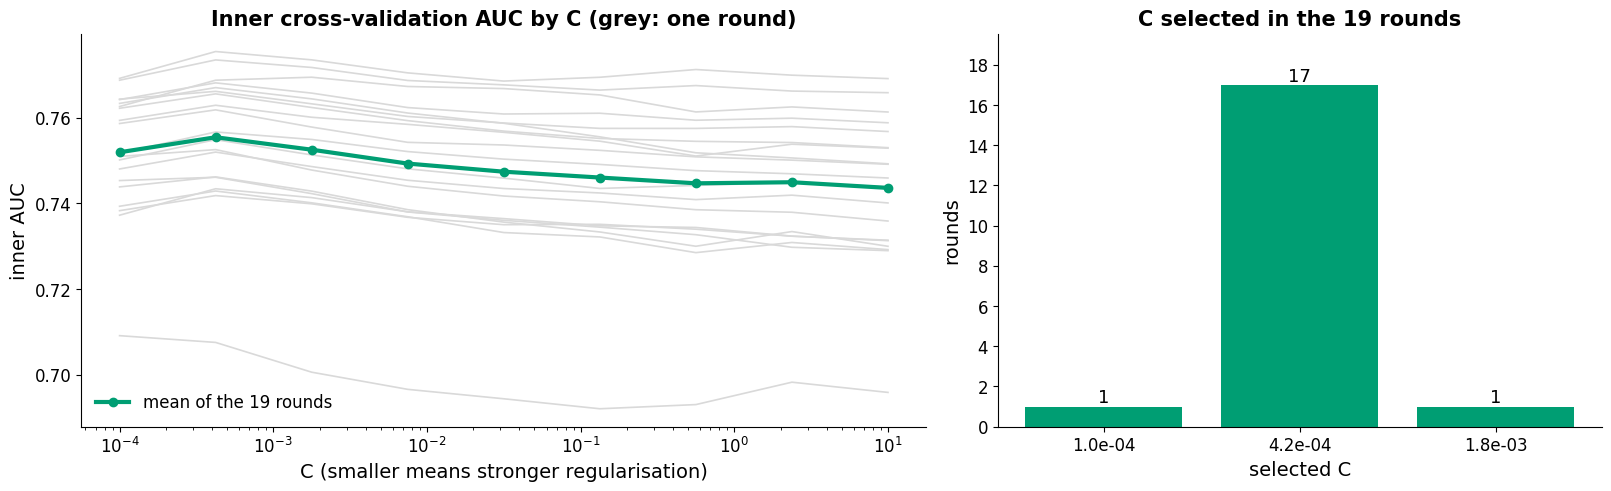

In [ ]:
# @title Figure 19. Selection of the regularisation strength C
fig, axs = plt.subplots(1, 2, figsize=(16, 4.8), width_ratios=[1.4, 1], layout="constrained")
for s in SITES:
    axs[0].semilogx(C_GRID, INNER_main[s], color=COL["light"], lw=1.2)
axs[0].semilogx(C_GRID, np.nanmean([INNER_main[s] for s in SITES], axis=0), color=COL["green"], lw=3,
                marker="o", label="mean of the 19 rounds")
axs[0].set_xlabel("C (smaller means stronger regularisation)"); axs[0].set_ylabel("inner AUC")
axs[0].legend(frameon=False); axs[0].set_title("Inner cross-validation AUC by C (grey: one round)")
vc = pd.Series([C_main[s] for s in SITES]).round(10).value_counts().sort_index()   # numeric order
axs[1].bar([f"{c_:.1e}" for c_ in vc.index], vc.values, color=COL["green"])
for k, v_ in enumerate(vc.values):
    axs[1].text(k, v_ + 0.2, v_, ha="center", fontsize=13)
axs[1].yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True)); axs[1].set_ylim(0, vc.values.max() * 1.15)
axs[1].set_xlabel("selected C"); axs[1].set_ylabel("rounds"); axs[1].set_title("C selected in the 19 rounds")
show_save(fig, "fig19_selection_of_C")

### 9.4 Comparison of shrinkage methods
The difference between the main model and the Ledoit-Wolf model is estimated by resampling sites with replacement 2,000 times, which accounts for participants from the same site being related. The rule, fixed in advance, is that condition-number matching counts as an improvement only if the 95% interval of the AUC difference lies entirely above zero.

In [ ]:
# 9.4 Difference between the two models, resampling sites
def site_bootstrap(pa, pb, reps=CONFIG["bootstrap_reps"], seed=CONFIG["bootstrap_seed"]):
    # difference (b minus a) in pooled AUC and in mean site balanced accuracy, resampling the 19 sites
    rng = np.random.default_rng(seed)
    ba_a = {s: ba(y[IDX[s]], pa[IDX[s]]) for s in SITES}; ba_b = {s: ba(y[IDX[s]], pb[IDX[s]]) for s in SITES}
    d_auc, d_ba = [], []
    for _ in range(reps):
        ss = rng.choice(SITES, len(SITES), replace=True)
        i = np.concatenate([IDX[s] for s in ss])
        d_auc.append(roc_auc_score(y[i], pb[i]) - roc_auc_score(y[i], pa[i]))
        d_ba.append(np.mean([ba_b[s] - ba_a[s] for s in ss]))
    return (np.mean(d_auc), *np.percentile(d_auc, [2.5, 97.5])), (np.mean(d_ba), *np.percentile(d_ba, [2.5, 97.5]))

(dA, loA, hiA), (dB, loB, hiB) = site_bootstrap(P_lw, P_main)
pd.DataFrame([{"comparison": "main minus Ledoit-Wolf", "d_AUC": dA, "AUC_95_low": loA, "AUC_95_high": hiA,
               "d_mean_site_balanced_accuracy": dB, "BA_95_low": loB, "BA_95_high": hiB}]
             ).to_csv(DIRS["04_results"] / "main_vs_ledoitwolf.csv", index=False)
print(f"AUC difference (main minus Ledoit-Wolf): {dA:+.3f}, 95% interval {loA:+.3f} to {hiA:+.3f}")
print(f"mean site balanced accuracy difference: {dB:+.3f}, 95% interval {loB:+.3f} to {hiB:+.3f}")
print("conclusion:", "improvement beyond uncertainty" if loA > 0 else
      ("main model worse" if hiA < 0 else "no difference beyond uncertainty"))

AUC difference (main minus Ledoit-Wolf): +0.028, 95% interval +0.014 to +0.043
mean site balanced accuracy difference: +0.019, 95% interval -0.004 to +0.046
conclusion: improvement beyond uncertainty


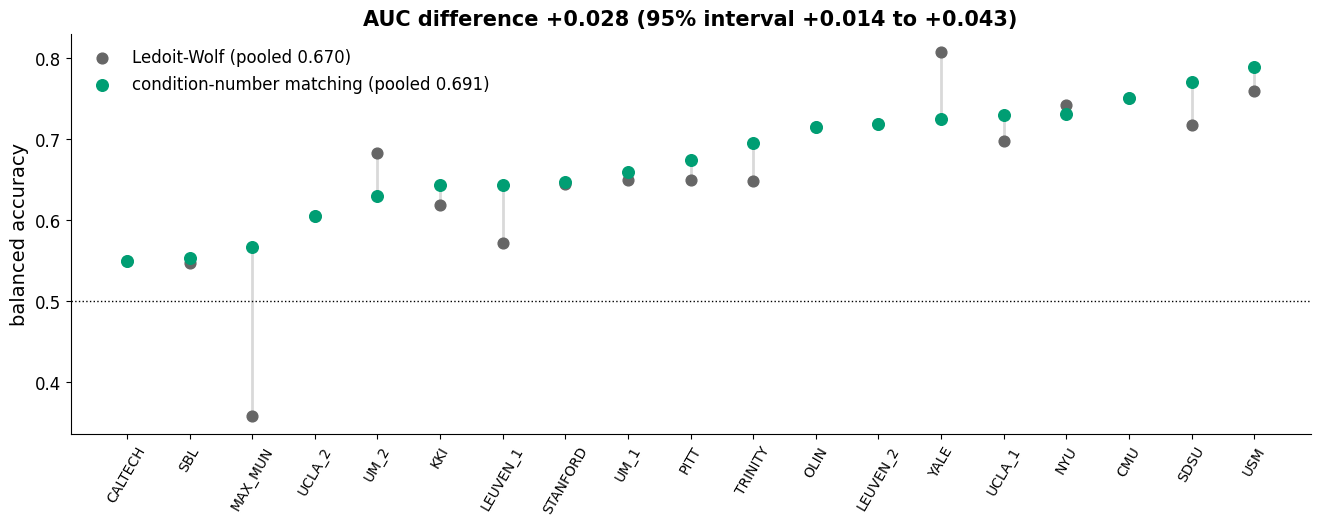

In [ ]:
# @title Figure 20. Balanced accuracy per site for both shrinkage methods
ps_lw = per_site(P_lw).set_index("site")["balanced_accuracy"]
ps_m = PS.set_index("site")["balanced_accuracy"]
order = ps_m.sort_values().index
fig, ax = plt.subplots(figsize=(16, 5.2))
xx = np.arange(len(order))
for k, s in enumerate(order):
    ax.plot([k, k], [ps_lw[s], ps_m[s]], color=COL["light"], lw=2)
ax.scatter(xx, ps_lw[order], color=COL["grey"], s=60, label=f"Ledoit-Wolf (pooled {ba(y, P_lw):.3f})", zorder=3)
ax.scatter(xx, ps_m[order], color=COL["green"], s=70, label=f"condition-number matching (pooled {ba(y, P_main):.3f})", zorder=3)
ax.axhline(0.5, color="black", ls=":", lw=1)
ax.set_xticks(xx); ax.set_xticklabels(order, rotation=60, fontsize=10); ax.set_ylabel("balanced accuracy")
ax.legend(frameon=False, loc="upper left")
ax.set_title(f"AUC difference {dA:+.3f} (95% interval {loA:+.3f} to {hiA:+.3f})")
show_save(fig, "fig20_shrinkage_comparison")

**Result.** AUC improved by 0.028 (95% interval 0.014 to 0.043), which meets the rule. The mean site balanced accuracy improved by 0.019, but its interval (-0.004 to 0.046) includes zero. The largest change was at MAX_MUN, one of the sites with the shortest scans, from 0.36 to 0.57; this fits the motivation in section 5.3, since Ledoit-Wolf shrinks short and long scans differently. Not every site improved: YALE dropped from 0.81 to 0.73 and UM_2 from 0.68 to 0.63.

# 10. Validity checks

### 10.1 Label permutation test
Could the model reach this score by chance, through quirks of the data rather than a real difference between the groups? To test this, the diagnoses are shuffled within each site and the full cross-validation is repeated (Ojala & Garriga, 2010). Shuffling breaks the link between brains and labels, while every site keeps its numbers of ASD and control participants:
```
real labels        A: ASD        B: control    C: ASD        D: control
shuffled labels    A: control    B: ASD        C: ASD        D: control
```
Repeating this 500 times gives the range of scores expected by chance for this pipeline. The p-value is the proportion of shuffled runs that score at least as high as the real labels; with 500 runs the smallest attainable value is 1/501, about 0.002 (Phipson & Smyth, 2010).

To keep the runtime to about one hour, C is fixed at the value selected most often in the main model (4.2e-4), and the features are stored in an exactly equivalent compressed form (section 14). The cell checks that this reproduces the main model's predictions. For this reason the observed AUC in this test (0.758) differs slightly from the main result (0.747).

In [ ]:
# 10.1 Label permutation test (about 1 hour the first time; saved every 10 permutations)
FOLDS = {s: dict(np.load(PERM_CACHE / f"round_{s}.npz")) for s in SITES}
vals, cnts = np.unique(np.round(list(C_main.values()), 10), return_counts=True)
C_FIX = float(vals[np.argmax(cnts)])
print(f"C selected in the main model: {dict(zip([f'{v:.1e}' for v in vals], cnts.tolist()))}; fixed C = {C_FIX:.1e}")

def loso_fixed(labels):
    p = np.full(N, np.nan)
    for s in SITES:
        f = FOLDS[s]
        p[f["te"]] = fit_lr(f["Rtr"], labels[f["tr"]], C_FIX).predict_proba(f["Rte"])[:, 1]
    return p

def perm_stats(labels, p):
    return [roc_auc_score(labels, p), ba(labels, p), np.mean([roc_auc_score(labels[IDX[s]], p[IDX[s]]) for s in SITES])]
STAT_NAMES = ["pooled AUC", "pooled balanced accuracy", "mean site AUC"]

P_fix = loso_fixed(y)
same = [s for s in SITES if np.isclose(C_main[s], C_FIX)]
d_same = max(np.max(np.abs(P_fix[IDX[s]] - P_main[IDX[s]])) for s in same)
print(f"check: in the {len(same)} rounds that selected C = {C_FIX:.1e}, the compressed features reproduce "
      f"the main model's predictions within {d_same:.4f}")
REAL = perm_stats(y, P_fix)

def shuffled(seed):
    rng = np.random.default_rng(seed); yp = y.copy()
    for s in SITES:
        yp[IDX[s]] = rng.permutation(y[IDX[s]])
    return yp

PF = DIRS["05_checks"] / "permutation_null.npz"
NP = CONFIG["n_permutations"]
NULL = np.full((NP, 3), np.nan)
if PF.exists():
    old = np.load(PF)["null"]; NULL[:min(NP, len(old))] = old[:NP]
start = int(np.isfinite(NULL[:, 0]).sum())
if start:
    log(f"permutation test: resuming at {start} of {NP}")
t0 = time.time()
for k in range(start, NP):
    yp = shuffled(CONFIG["perm_seed_base"] + k)             # fixed seeds make the test reproducible and resumable
    NULL[k] = perm_stats(yp, loso_fixed(yp))
    if (k + 1) % 10 == 0 or k + 1 == NP:
        save_npz(PF, null=NULL, real=np.array(REAL), C_fix=C_FIX)
        rate = (time.time() - t0) / (k + 1 - start)
        print(f"  {k + 1} of {NP} permutations | highest permuted AUC so far {np.nanmax(NULL[:k + 1, 0]):.3f} "
              f"| about {rate * (NP - k - 1) / 60:.0f} min remaining", flush=True)

done = np.isfinite(NULL[:, 0]); n_done = int(done.sum())
PT = pd.DataFrame([{"statistic": nm, "observed": REAL[j], "permuted_mean": NULL[done, j].mean(),
                    "permuted_95th_percentile": np.percentile(NULL[done, j], 95), "permuted_max": NULL[done, j].max(),
                    "p_value": (1 + int((NULL[done, j] >= REAL[j]).sum())) / (1 + n_done)}
                   for j, nm in enumerate(STAT_NAMES)])
PT.to_csv(DIRS["05_checks"] / "permutation_test.csv", index=False)
print(PT.round(4).to_string(index=False))
print(f"smallest attainable p-value with {n_done} permutations: {1 / (1 + n_done):.4f}")

C selected in the main model: {'1.0e-04': 1, '4.2e-04': 17, '1.8e-03': 1}; fixed C = 4.2e-04
check: in the 17 rounds that selected C = 4.2e-04, the compressed features reproduce the main model's predictions within 0.0007
2026-10-20 18:12:18  permutation test: resuming at 500 of 500
               statistic  observed  permuted_mean  permuted_95th_percentile  permuted_max  p_value
              pooled AUC    0.7580         0.5038                    0.5482        0.5761    0.002
pooled balanced accuracy    0.6902         0.5018                    0.5377        0.5580    0.002
           mean site AUC    0.7616         0.4958                    0.5468        0.5865    0.002
smallest attainable p-value with 500 permutations: 0.0020


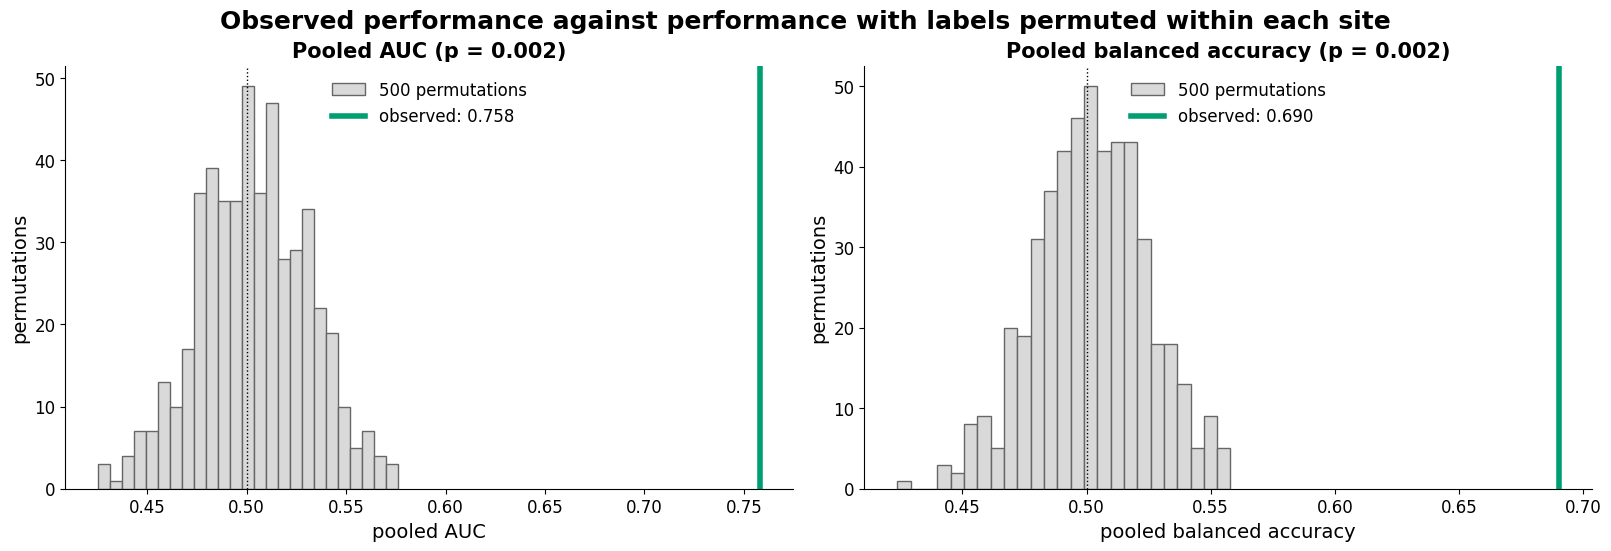

In [ ]:
# @title Figure 21. Label permutation test
fig, axs = plt.subplots(1, 2, figsize=(16, 5.4), layout="constrained")
for ax, j, nm in zip(axs, [0, 1], ["Pooled AUC", "Pooled balanced accuracy"]):
    ax.hist(NULL[done, j], bins=25, color=COL["light"], edgecolor=COL["grey"], label=f"{n_done} permutations")
    ax.axvline(REAL[j], color=COL["green"], lw=4, label=f"observed: {REAL[j]:.3f}")
    ax.axvline(0.5, color="black", ls=":", lw=1)
    ax.set_xlabel(nm[0].lower() + nm[1:]); ax.set_ylabel("permutations")
    ax.set_title(f"{nm} (p = {PT.loc[j, 'p_value']:.3f})")
    ax.legend(frameon=False, loc="upper center")
fig.suptitle("Observed performance against performance with labels permuted within each site")
show_save(fig, "fig21_permutation_test")

**Result.** The 500 shuffled runs reached an AUC of 0.504 on average and never more than 0.576, against 0.758 with the real labels. The same holds for balanced accuracy and the mean site AUC (p = 0.002 for all three, the smallest attainable value).

### 10.2 Head motion
Participants with ASD moved more in this sample, and motion affects connectivity estimates. Four analyses assess its influence:
1. **Motion-only model.** The same classifier and cross-validation, using only mean FD and the percentage of high-motion volumes as features.
2. **Association between predictions and motion.** Rank correlation between the predicted probability and FD within each combination of site and diagnosis, so that neither can produce the association.
3. **Motion-matched pairs.** Within each site, each ASD participant is paired with a control whose FD differs by at most 0.01 mm, and the proportion of pairs in which the ASD participant scores higher is compared with the same proportion across all ASD and control pairs. If predictions depended on motion, matching would move this proportion toward 0.5.
4. **Mean connectivity and motion.** Rank correlation between each participant's mean connectivity and FD, within site and diagnosis. Motion introduces artefactual signal that affects many connections at once (Power et al., 2012; Satterthwaite et al., 2012).

The same within-group correlations are reported for age and scan length.

In [ ]:
# 10.2 Head-motion analyses
# (1) motion-only model with the same nested selection and leave-one-site-out evaluation
Xm = np.c_[fd, perc_fd]
P_motion = np.full(N, np.nan)
for s in SITES:
    tr, te = np.where(site != s)[0], IDX[s]
    med = np.nanmedian(Xm[tr], axis=0)                      # missing values replaced by the training median
    Xtr_, Xte_ = np.where(np.isnan(Xm[tr]), med, Xm[tr]), np.where(np.isnan(Xm[te]), med, Xm[te])
    scm = StandardScaler().fit(Xtr_)
    P_motion[te] = tune_and_fit(scm.transform(Xtr_), y[tr], scm.transform(Xte_), site[tr])[0]

# (2) association of the predictions with motion, age and scan length within site and diagnosis
rho_fd, rho_age, rho_T = within_rho(P_main, fd, GROUP), within_rho(P_main, age, GROUP), within_rho(P_main, T_sub, GROUP)

# (3) motion-matched pairs against all pairs within sites
def pair_score(p, conf=None, tol=None, seed=CONFIG["matched_seed"]):
    rng = np.random.default_rng(seed); wins = []
    for s in SITES:
        ia = np.where((site == s) & (y == 1))[0]; ic = list(np.where((site == s) & (y == 0))[0])
        if conf is None:                                     # all ASD and control pairs
            for i in ia:
                for j in ic:
                    wins.append(1.0 if p[i] > p[j] else (0.5 if p[i] == p[j] else 0.0))
            continue
        for i in rng.permutation(ia):                        # greedy matching on the nearest FD
            if not ic:
                break
            j = min(ic, key=lambda k: abs(conf[k] - conf[i]))
            if abs(conf[j] - conf[i]) > tol:
                continue
            ic.remove(j)
            wins.append(1.0 if p[i] > p[j] else (0.5 if p[i] == p[j] else 0.0))
    return float(np.mean(wins)), len(wins)
auc_all_pairs, n_all_pairs = pair_score(P_main)
auc_matched, n_matched = pair_score(P_main, fd, CONFIG["matched_fd_tolerance_mm"])

# (4) mean connectivity (average correlation over region pairs) against motion
mean_r = np.empty(N)
for i in range(N):
    a = ~dead[i]; S_ = S_full[i][np.ix_(a, a)]; d_ = np.sqrt(np.diag(S_))
    mean_r[i] = (S_ / np.outer(d_, d_))[np.triu_indices(a.sum(), 1)].mean()
rho_level = within_rho(mean_r, fd, GROUP)

MOT = pd.DataFrame([
    {"analysis": "connectivity model, pooled AUC", "value": roc_auc_score(y, P_main)},
    {"analysis": "motion-only model, pooled AUC", "value": roc_auc_score(y, P_motion)},
    {"analysis": "motion-only model, balanced accuracy", "value": ba(y, P_motion)},
    {"analysis": "prediction vs FD, rank correlation within site and diagnosis", "value": rho_fd},
    {"analysis": "prediction vs age, rank correlation within site and diagnosis", "value": rho_age},
    {"analysis": "prediction vs scan length, rank correlation within site and diagnosis", "value": rho_T},
    {"analysis": f"all within-site pairs ({n_all_pairs}), proportion with ASD scored higher", "value": auc_all_pairs},
    {"analysis": f"motion-matched pairs ({n_matched}), proportion with ASD scored higher", "value": auc_matched},
    {"analysis": "mean connectivity vs FD, rank correlation within site and diagnosis", "value": rho_level}])
MOT.to_csv(DIRS["05_checks"] / "motion_analyses.csv", index=False)
print(MOT.round(3).to_string(index=False))

                                                             analysis  value
                                       connectivity model, pooled AUC  0.747
                                        motion-only model, pooled AUC  0.579
                                 motion-only model, balanced accuracy  0.567
         prediction vs FD, rank correlation within site and diagnosis  0.292
        prediction vs age, rank correlation within site and diagnosis -0.138
prediction vs scan length, rank correlation within site and diagnosis  0.044
     all within-site pairs (14856), proportion with ASD scored higher  0.792
        motion-matched pairs (251), proportion with ASD scored higher  0.777
  mean connectivity vs FD, rank correlation within site and diagnosis  0.497


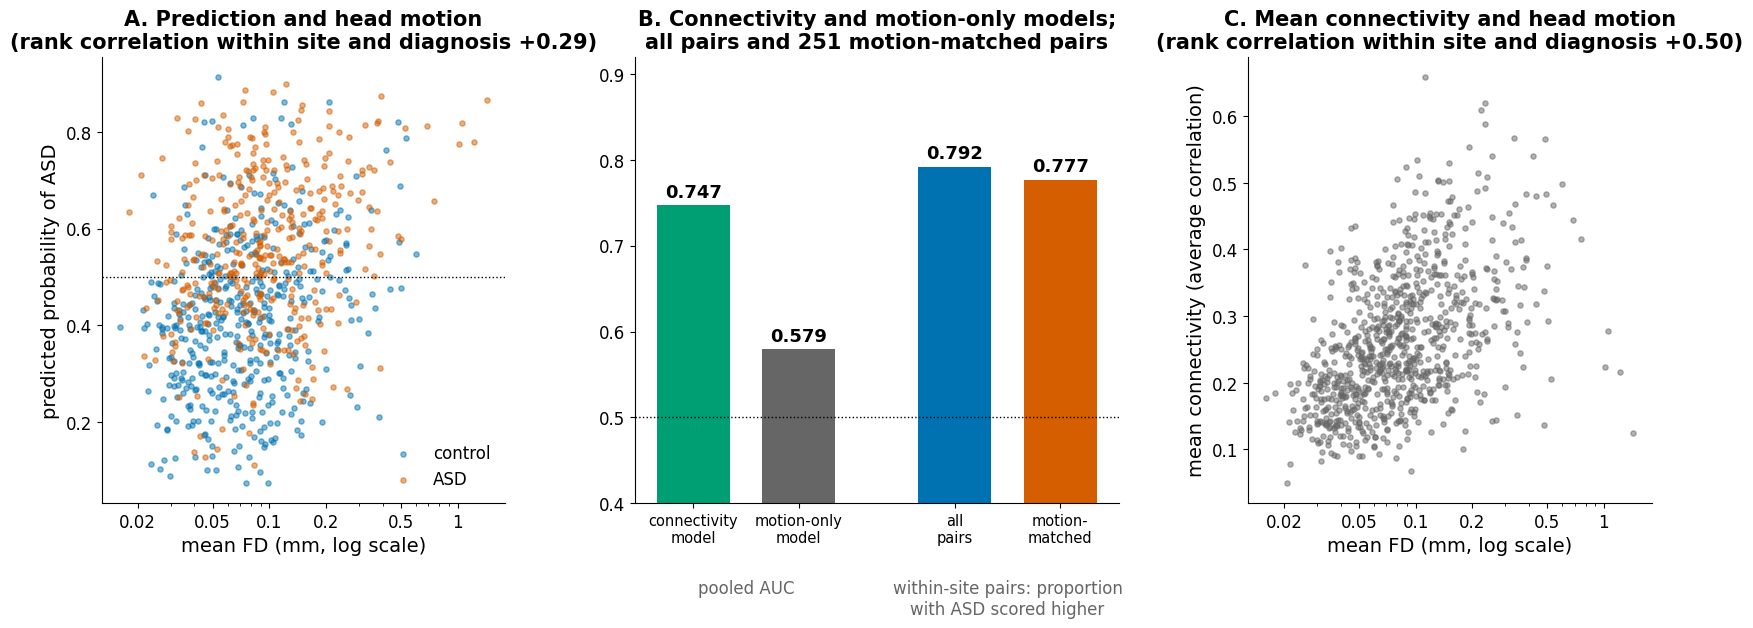

In [ ]:
# @title Figure 22. Head-motion analyses
fig, axs = plt.subplots(1, 3, figsize=(20, 5.8), gridspec_kw=dict(wspace=0.3, width_ratios=[1, 1.2, 1]))
ax = axs[0]
for g, c, lab in [(0, COL["ctrl"], "control"), (1, COL["asd"], "ASD")]:
    m = y == g
    ax.scatter(fd[m], P_main[m], s=14, alpha=0.5, color=c, label=lab)
log_axis(ax); ax.axhline(0.5, color="black", ls=":", lw=1)
ax.set_xlabel("mean FD (mm, log scale)"); ax.set_ylabel("predicted probability of ASD")
ax.legend(frameon=False, loc="lower right")
ax.set_title(f"A. Prediction and head motion\n(rank correlation within site and diagnosis {rho_fd:+.2f})")

ax = axs[1]
bars = [("connectivity\nmodel", roc_auc_score(y, P_main), COL["green"]),
        ("motion-only\nmodel", roc_auc_score(y, P_motion), COL["grey"]),
        ("all\npairs", auc_all_pairs, COL["ctrl"]),
        ("motion-\nmatched", auc_matched, COL["asd"])]
xpos = [0, 1.15, 2.85, 4.0]
for x_, (lab, v_, c) in zip(xpos, bars):
    ax.bar(x_, v_, color=c, width=0.8)
    ax.text(x_, v_ + 0.01, f"{v_:.3f}", ha="center", fontsize=13, weight="bold")
ax.axhline(0.5, color="black", ls=":", lw=1); ax.set_ylim(0.4, max(0.92, max(b[1] for b in bars) + 0.07))
ax.set_xticks(xpos); ax.set_xticklabels([b[0] for b in bars], fontsize=10.5)
ax.text(0.575, -0.17, "pooled AUC", ha="center", va="top", fontsize=12, color=COL["grey"],
        transform=ax.get_xaxis_transform())
ax.text(3.425, -0.17, "within-site pairs: proportion\nwith ASD scored higher", ha="center", va="top", fontsize=12,
        color=COL["grey"], transform=ax.get_xaxis_transform())
ax.set_title(f"B. Connectivity and motion-only models;\nall pairs and {n_matched} motion-matched pairs")

ax = axs[2]
ax.scatter(fd, mean_r, s=14, alpha=0.5, color=COL["grey"])
log_axis(ax); ax.set_xlabel("mean FD (mm, log scale)")
ax.set_ylabel("mean connectivity (average correlation)")
ax.set_title(f"C. Mean connectivity and head motion\n(rank correlation within site and diagnosis {rho_level:+.2f})")
show_save(fig, "fig22_head_motion")

**Result.**
* Motion alone predicts diagnosis only weakly (AUC 0.58, balanced accuracy 0.57), far below connectivity (AUC 0.75).
* Predictions are partly associated with motion: rank correlation +0.29 within site and diagnosis.
* In 251 motion-matched pairs the ASD participant scored higher in 77.7% of pairs, close to 79.2% across all 14,856 within-site pairs, so matching on motion barely changes the ranking.
* Mean connectivity rises with motion (rank correlation +0.50): head motion raises correlations across the whole brain.
* Predictions are weakly associated with age (-0.14) and not with scan length (+0.04).

The classification is therefore not explained by head motion, but the model is not free of motion effects.

# 11. Comparison with Abraham et al. (2017)

Abraham et al. found MSDL significantly better than all other atlases except the predefined Harvard-Oxford atlas; here, cc200 performed at least as well as the five other atlases tested.

* **Participants.** Both started from the same 871 quality-checked participants. This analysis additionally excluded 25 scans with fewer than 100 time points.
* **Preprocessing.** Both used motion, CompCor and drift regression without global signal regression. This analysis also used band-pass filtering, which the paper does not mention.
* **Regions.** Abraham et al. learned atlases from the training data, with MSDL performing best. This analysis used the predefined cc200 atlas; Abraham et al. found predefined atlases only slightly less accurate, and cc200 performed at least as well as the five other atlases tested here.
* **Shrinkage.** Abraham et al. used Ledoit-Wolf. This analysis used condition-number matching, which makes every matrix equally stable regardless of scan length and raised AUC from 0.718 to 0.747 within the same pipeline (section 9.4).
* **Connectivity representation.** Tangent space in both.
* **Classifier.** Abraham et al. used an L2-regularised SVM or ridge classifier and reported similar results for logistic regression. This analysis used L2-regularised logistic regression, which outputs the probabilities needed for AUC and the motion analyses.
* **Confounds.** Abraham et al. regressed site, age and sex out of the connectivity features. Here these variables were excluded from the model and used only in checks.
* **Cross-validation.** Abraham et al. used 10 folds with whole sites held out. This analysis used 19 folds, one site per fold.
* **Metric.** Abraham et al. reported accuracy, whose chance level depends on group sizes. This analysis reports balanced accuracy and AUC, whose chance level is 0.5.

The Ledoit-Wolf comparison model (section 8.6), which follows their pipeline with the cc200 atlas, reached a plain accuracy of 0.671, close to their 0.668.

# 12. Alternative approaches tested

Each alternative used the same data, folds and classifier as the final model. None improved performance beyond the uncertainty of the estimate. They are summarised here and not re-run; values are balanced accuracy and AUC.

* **Final model:** 0.691 and 0.747.
* **Ledoit-Wolf shrinkage:** 0.670 and 0.718. Re-run in sections 8.6 and 9.4.
* **Shrinkage target of 30:** 0.691 and 0.754. No difference.
* **Other atlases:** ez 0.685 and 0.747; ho 0.670 and 0.733; tt 0.665 and 0.732; aal 0.665 and 0.738; dosenbach160 0.609 and 0.659. cc200 performed at least as well as each of them.
* **Average of six atlases:** 0.680 and 0.758. Within uncertainty.
* **Site-specific reference matrices:** 0.694 and 0.758. Within uncertainty; this approach also requires data from each new site before prediction.
* **Graph measures** (degree, strength, clustering, eigenvector centrality and betweenness for each region): 0.580 and 0.620. Worse.
* **Mean absolute tangent value per region:** 0.553 and 0.581. Worse.
* **Tangent features combined with graph measures:** 0.681 and 0.755. No difference.
* **MAX_MUN excluded from training,** evaluated on the remaining 18 sites: 0.690 against 0.698, and 0.752 against 0.756. Within uncertainty.
* **Global signal regression:** 0.680 and 0.735. Slightly worse.

Region-level summaries reduce about 178 connections per region to a single value and lose information about which specific connections differ. The diagnostic information appears to be distributed across many individual connections.

# 13. Limitations and future work

**Limitations**
* The shrinkage target was evaluated on the same sites reported here, so performance may be slightly overestimated. Targets of 30 and 100 gave the same balanced accuracy, which suggests the effect is small.
* Head motion raises connectivity across the whole brain, and predictions remain partly associated with motion (section 10.2), although classification persists in motion-matched pairs.
* Regions at the edges of the brain (frontal pole, orbitofrontal cortex, temporal pole, parts of the cerebellum) are removed because some participants have no signal there, so the model cannot use them.
* At several sites all predictions are shifted, so the 0.5 threshold misclassifies many participants even when the ranking is good (section 9.2).
* Site-level results are uncertain because of small site samples.
* All results come from ABIDE I. No official preprocessed release of ABIDE II was found, so external validation would require independent preprocessing.
* A balanced accuracy of about 0.69 means roughly three in ten participants are misclassified. The model describes group-level differences and is not a diagnostic tool.

**Future work**
* Identify the connections and networks that drive classification. Model weights can be misleading when features are correlated, so they will be converted to activation patterns (Haufe et al., 2014), mapped to anatomy and grouped into functional networks. This work has started in a separate exploration notebook.
* Harmonise scanner effects across sites and validate on ABIDE II.

# 14. Technical notes

* **Covariance:** $\Sigma_{ij}=\frac{1}{T}\sum_t (x_i(t)-\bar x_i)(x_j(t)-\bar x_j)$, dividing by $T$ as in scikit-learn's covariance estimators.
* **Shrinkage:** $C=(1-\alpha)S+\alpha mI$, where $m$ is the mean variance. Condition-number matching uses $\alpha=\frac{\lambda_{max}-\kappa\lambda_{min}}{m(\kappa-1)+\lambda_{max}-\kappa\lambda_{min}}$ with $\kappa=100$, and $\alpha=0$ if the condition number is already below $\kappa$.
* **Reference matrix:** Riemannian geometric mean, computed iteratively from the arithmetic mean with at most 15 iterations and tolerance $10^{-3}$; the step size is halved whenever the gradient norm increases.
* **Tangent projection:** $T=\log\big(\mathrm{ref}^{-1/2}\,C\,\mathrm{ref}^{-1/2}\big)$.
* **Vectorisation:** lower triangle including the diagonal, with diagonal entries divided by $\sqrt{2}$ (the nilearn convention). With 179 regions this gives 179 diagonal and 15,931 off-diagonal values, 16,110 in total; some folds retain up to 183 regions.
* **Classifier:** scikit-learn logistic regression minimising $\tfrac12\lVert w\rVert^2 + C\sum_i \ell_i$, where $\ell_i$ is the class-weighted log loss. C is selected from nine values between $10^{-4}$ and $10$.
* **Permutation p-value:** $p=\frac{1+\#\{\text{permuted}\geq\text{observed}\}}{1+n_{\text{perm}}}$.
* **Compressed features for the permutation test:** the solution of an L2-regularised linear model lies in the span of its training samples, so the standardised features are projected onto the right singular vectors of the training matrix (about 830 dimensions instead of 16,110). This leaves predictions unchanged up to solver tolerance, and because the projection uses no labels it remains valid under permutation.

# 15. References

* Abraham, A., Milham, M. P., Di Martino, A., Craddock, R. C., Samaras, D., Thirion, B., & Varoquaux, G. (2017). Deriving reproducible biomarkers from multi-site resting-state data: an autism-based example. *NeuroImage*, 147, 736-745. https://doi.org/10.1016/j.neuroimage.2016.10.045
* Behzadi, Y., Restom, K., Liau, J., & Liu, T. T. (2007). A component based noise correction method (CompCor) for BOLD and perfusion based fMRI. *NeuroImage*, 37(1), 90-101. https://doi.org/10.1016/j.neuroimage.2007.04.042
* Biswal, B., Yetkin, F. Z., Haughton, V. M., & Hyde, J. S. (1995). Functional connectivity in the motor cortex of resting human brain using echo-planar MRI. *Magnetic Resonance in Medicine*, 34(4), 537-541. https://doi.org/10.1002/mrm.1910340409
* Brodersen, K. H., Ong, C. S., Stephan, K. E., & Buhmann, J. M. (2010). The balanced accuracy and its posterior distribution. In *20th International Conference on Pattern Recognition*, 3121-3124. https://doi.org/10.1109/ICPR.2010.764
* Craddock, R. C., James, G. A., Holtzheimer, P. E., Hu, X. P., & Mayberg, H. S. (2012). A whole brain fMRI atlas generated via spatially constrained spectral clustering. *Human Brain Mapping*, 33(8), 1914-1928. https://doi.org/10.1002/hbm.21333
* Craddock, C., Benhajali, Y., Chu, C., Chouinard, F., Evans, A., Jakab, A., Khundrakpam, B. S., Lewis, J. D., Li, Q., Milham, M., Yan, C., & Bellec, P. (2013). The Neuro Bureau Preprocessing Initiative: open sharing of preprocessed neuroimaging data and derivatives. *Frontiers in Neuroinformatics*, Conference Abstract: Neuroinformatics 2013. https://doi.org/10.3389/conf.fninf.2013.09.00041
* Dadi, K., Rahim, M., Abraham, A., Chyzhyk, D., Milham, M., Thirion, B., & Varoquaux, G. (2019). Benchmarking functional connectome-based predictive models for resting-state fMRI. *NeuroImage*, 192, 115-134. https://doi.org/10.1016/j.neuroimage.2019.02.062
* Deen, B., & Pelphrey, K. (2012). Perspective: brain scans need a rethink. *Nature*, 491(7422), S20. https://doi.org/10.1038/491S20a
* Di Martino, A., Yan, C.-G., Li, Q., et al. (2014). The autism brain imaging data exchange: towards a large-scale evaluation of the intrinsic brain architecture in autism. *Molecular Psychiatry*, 19(6), 659-667. https://doi.org/10.1038/mp.2013.78
* Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters*, 27(8), 861-874. https://doi.org/10.1016/j.patrec.2005.10.010
* Friston, K. J., Williams, S., Howard, R., Frackowiak, R. S., & Turner, R. (1996). Movement-related effects in fMRI time-series. *Magnetic Resonance in Medicine*, 35(3), 346-355. https://doi.org/10.1002/mrm.1910350312
* Gotts, S. J., Saad, Z. S., Jo, H. J., Wallace, G. L., Cox, R. W., & Martin, A. (2013). The perils of global signal regression for group comparisons: a case study of Autism Spectrum Disorders. *Frontiers in Human Neuroscience*, 7, 356. https://doi.org/10.3389/fnhum.2013.00356
* Haufe, S., Meinecke, F., Görgen, K., Dähne, S., Haynes, J.-D., Blankertz, B., & Bießmann, F. (2014). On the interpretation of weight vectors of linear models in multivariate neuroimaging. *NeuroImage*, 87, 96-110. https://doi.org/10.1016/j.neuroimage.2013.10.067
* Ledoit, O., & Wolf, M. (2004). A well-conditioned estimator for large-dimensional covariance matrices. *Journal of Multivariate Analysis*, 88(2), 365-411. https://doi.org/10.1016/S0047-259X(03)00096-4
* Moakher, M. (2005). A differential geometric approach to the geometric mean of symmetric positive-definite matrices. *SIAM Journal on Matrix Analysis and Applications*, 26(3), 735-747. https://doi.org/10.1137/S0895479803436937
* Murphy, K., Birn, R. M., Handwerker, D. A., Jones, T. B., & Bandettini, P. A. (2009). The impact of global signal regression on resting state correlations: are anti-correlated networks introduced? *NeuroImage*, 44(3), 893-905. https://doi.org/10.1016/j.neuroimage.2008.09.036
* Ojala, M., & Garriga, G. C. (2010). Permutation tests for studying classifier performance. *Journal of Machine Learning Research*, 11, 1833-1863. https://www.jmlr.org/papers/v11/ojala10a.html
* Pennec, X., Fillard, P., & Ayache, N. (2006). A Riemannian framework for tensor computing. *International Journal of Computer Vision*, 66(1), 41-66. https://doi.org/10.1007/s11263-005-3222-z
* Phipson, B., & Smyth, G. K. (2010). Permutation P-values should never be zero: calculating exact P-values when permutations are randomly drawn. *Statistical Applications in Genetics and Molecular Biology*, 9(1), Article 39. https://doi.org/10.2202/1544-6115.1585
* Power, J. D., Barnes, K. A., Snyder, A. Z., Schlaggar, B. L., & Petersen, S. E. (2012). Spurious but systematic correlations in functional connectivity MRI networks arise from subject motion. *NeuroImage*, 59(3), 2142-2154. https://doi.org/10.1016/j.neuroimage.2011.10.018
* Satterthwaite, T. D., Wolf, D. H., Loughead, J., Ruparel, K., Elliott, M. A., Hakonarson, H., Gur, R. C., & Gur, R. E. (2012). Impact of in-scanner head motion on multiple measures of functional connectivity: relevance for studies of neurodevelopment in youth. *NeuroImage*, 60(1), 623-632. https://doi.org/10.1016/j.neuroimage.2011.12.063
* Van Dijk, K. R. A., Sabuncu, M. R., & Buckner, R. L. (2012). The influence of head motion on intrinsic functional connectivity MRI. *NeuroImage*, 59(1), 431-438. https://doi.org/10.1016/j.neuroimage.2011.07.044
* Varma, S., & Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics*, 7, 91. https://doi.org/10.1186/1471-2105-7-91
* Varoquaux, G., Baronnet, F., Kleinschmidt, A., Fillard, P., & Thirion, B. (2010). Detection of brain functional-connectivity difference in post-stroke patients using group-level covariance modeling. In *Medical Image Computing and Computer-Assisted Intervention, MICCAI 2010*, Lecture Notes in Computer Science, 200-208. Springer. https://doi.org/10.1007/978-3-642-15705-9_25
* Varoquaux, G., Raamana, P. R., Engemann, D. A., Hoyos-Idrobo, A., Schwartz, Y., & Thirion, B. (2017). Assessing and tuning brain decoders: cross-validation, caveats, and guidelines. *NeuroImage*, 145, 166-179. https://doi.org/10.1016/j.neuroimage.2016.10.038
* Varoquaux, G. (2018). Cross-validation failure: small sample sizes lead to large error bars. *NeuroImage*, 180, 68-77. https://doi.org/10.1016/j.neuroimage.2017.06.061
* Won, J.-H., Lim, J., Kim, S.-J., & Rajaratnam, B. (2013). Condition-number-regularized covariance estimation. *Journal of the Royal Statistical Society: Series B*, 75(3), 427-450. https://doi.org/10.1111/j.1467-9868.2012.01049.x